# Converting Energy Demand and Power Production TSF to Pandas Dataframe
Essentialy, this is just imported code from a github repository provided. It takes the TSF data file and converts it into a Pandas Dataframe for use in Python  

In [1]:
from datetime import datetime
from distutils.util import strtobool

import pandas as pd


# Converts the contents in a .tsf file into a dataframe and returns it along with other meta-data of the dataset: frequency, horizon, whether the dataset contains missing values and whether the series have equal lengths
#
# Parameters
# full_file_path_and_name - complete .tsf file path
# replace_missing_vals_with - a term to indicate the missing values in series in the returning dataframe
# value_column_name - Any name that is preferred to have as the name of the column containing series values in the returning dataframe
def convert_tsf_to_dataframe(
    full_file_path_and_name,
    replace_missing_vals_with="NaN",
    value_column_name="series_value",
):
    col_names = []
    col_types = []
    all_data = {}
    line_count = 0
    frequency = None
    forecast_horizon = None
    contain_missing_values = None
    contain_equal_length = None
    found_data_tag = False
    found_data_section = False
    started_reading_data_section = False

    with open(full_file_path_and_name, "r", encoding="cp1252") as file:
        for line in file:
            # Strip white space from start/end of line
            line = line.strip()

            if line:
                if line.startswith("@"):  # Read meta-data
                    if not line.startswith("@data"):
                        line_content = line.split(" ")
                        if line.startswith("@attribute"):
                            if (
                                len(line_content) != 3
                            ):  # Attributes have both name and type
                                raise Exception("Invalid meta-data specification.")

                            col_names.append(line_content[1])
                            col_types.append(line_content[2])
                        else:
                            if (
                                len(line_content) != 2
                            ):  # Other meta-data have only values
                                raise Exception("Invalid meta-data specification.")

                            if line.startswith("@frequency"):
                                frequency = line_content[1]
                            elif line.startswith("@horizon"):
                                forecast_horizon = int(line_content[1])
                            elif line.startswith("@missing"):
                                contain_missing_values = bool(
                                    strtobool(line_content[1])
                                )
                            elif line.startswith("@equallength"):
                                contain_equal_length = bool(strtobool(line_content[1]))

                    else:
                        if len(col_names) == 0:
                            raise Exception(
                                "Missing attribute section. Attribute section must come before data."
                            )

                        found_data_tag = True
                elif not line.startswith("#"):
                    if len(col_names) == 0:
                        raise Exception(
                            "Missing attribute section. Attribute section must come before data."
                        )
                    elif not found_data_tag:
                        raise Exception("Missing @data tag.")
                    else:
                        if not started_reading_data_section:
                            started_reading_data_section = True
                            found_data_section = True
                            all_series = []

                            for col in col_names:
                                all_data[col] = []

                        full_info = line.split(":")

                        if len(full_info) != (len(col_names) + 1):
                            raise Exception("Missing attributes/values in series.")

                        series = full_info[len(full_info) - 1]
                        series = series.split(",")

                        if len(series) == 0:
                            raise Exception(
                                "A given series should contains a set of comma separated numeric values. At least one numeric value should be there in a series. Missing values should be indicated with ? symbol"
                            )

                        numeric_series = []

                        for val in series:
                            if val == "?":
                                numeric_series.append(replace_missing_vals_with)
                            else:
                                numeric_series.append(float(val))

                        if numeric_series.count(replace_missing_vals_with) == len(
                            numeric_series
                        ):
                            raise Exception(
                                "All series values are missing. A given series should contains a set of comma separated numeric values. At least one numeric value should be there in a series."
                            )

                        all_series.append(pd.Series(numeric_series).array)

                        for i in range(len(col_names)):
                            att_val = None
                            if col_types[i] == "numeric":
                                att_val = int(full_info[i])
                            elif col_types[i] == "string":
                                att_val = str(full_info[i])
                            elif col_types[i] == "date":
                                att_val = datetime.strptime(
                                    full_info[i], "%Y-%m-%d %H-%M-%S"
                                )
                            else:
                                raise Exception(
                                    "Invalid attribute type."
                                )  # Currently, the code supports only numeric, string and date types. Extend this as required.

                            if att_val is None:
                                raise Exception("Invalid attribute value.")
                            else:
                                all_data[col_names[i]].append(att_val)

                line_count = line_count + 1

        if line_count == 0:
            raise Exception("Empty file.")
        if len(col_names) == 0:
            raise Exception("Missing attribute section.")
        if not found_data_section:
            raise Exception("Missing series information under data section.")

        all_data[value_column_name] = all_series
        loaded_data = pd.DataFrame(all_data)

        return (
            loaded_data,
            frequency,
            forecast_horizon,
            contain_missing_values,
            contain_equal_length,
        )


# Example of usage
# loaded_data, frequency, forecast_horizon, contain_missing_values, contain_equal_length = convert_tsf_to_dataframe("TSForecasting/tsf_data/sample.tsf")

# print(loaded_data)
# print(frequency)
# print(forecast_horizon)
# print(contain_missing_values)
# print(contain_equal_length)

In [2]:
testing_dataset = convert_tsf_to_dataframe(r"/mnt/c/Users/alpay/Downloads/phase_1_data.tsf",replace_missing_vals_with="NaN",value_column_name="series_value")

# Converting the Solar DataFrame to a Timeseries
To actually analyse the data, the dataframe has to be converted to a timeseries dataframe. Originally, the dataset from converting the dataset only provided each Building and Respective Solar, the time which the data for each buildings data starts, and the actual values of the time series in a list.

Essentially a new dataset was made with index starting from the earliest recorded time from all the buildings and Solar, to the end of September, as according to the project. After, the Buildings and Solar from the original data set were made the columns of the new time_series data set.

To fill in the new dataset, the list of the time series for each building were set to start when the timestamp was, alllocated to the specific timeseries row in the new dataset. With this, the new dataset was now a timeseries with all values for each building and solar in each correct sport respecitvely.

In [3]:
real_set = testing_dataset[0]
real_set


,series_name,start_timestamp,series_value
0,Building0,2016-07-03 21:30:00,"[283.8, 283.8, 283.8, 606.0, 606.0, 606.0, 606..."
1,Building1,2019-01-09 23:15:00,"[8.1, 15.7, 22.8, 32.7, 8.1, 16.5, 24.7, 34.5,..."
2,Building3,2016-03-01 04:15:00,"[1321.0, 1321.0, 1321.0, 1321.0, 1293.0, 1293...."
3,Building4,2019-07-03 04:45:00,"[2.0, NaN, 1.0, 2.0, NaN, 2.0, NaN, NaN, 2.0, ..."
4,Building5,2019-07-25 23:00:00,"[30.0, 31.0, 24.0, 34.0, 30.0, 31.0, 26.0, 33...."
5,Building6,2019-07-25 01:45:00,"[36.8, 34.6, 34.6, 36.2, 36.2, 35.2, 35.2, 35...."
6,Solar0,2020-04-25 14:00:00,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
7,Solar1,2018-12-31 13:00:00,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
8,Solar2,2019-06-05 14:00:00,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
9,Solar3,2019-06-05 14:00:00,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [4]:
index = pd.date_range(start="2016-03-01 04:15:00", end="2020-09-30 23:59:45", freq="15min")
new_headers = real_set["series_name"].dropna().unique().tolist()

series_testing_dataset = pd.DataFrame(columns = new_headers,index = index)

for _, row in real_set.iterrows():

    column = row.series_name
    start_time = pd.to_datetime(row.start_timestamp)
    values = row.series_value

    start_time_index = series_testing_dataset.index.get_loc(start_time)

    series_testing_dataset.iloc[0:start_time_index, series_testing_dataset.columns.get_loc(column)] = 0
    series_testing_dataset.iloc[start_time_index:start_time_index + len(values),series_testing_dataset.columns.get_loc(column)] = values

series_testing_dataset = series_testing_dataset.apply(pd.to_numeric,errors='coerce')
series_testing_dataset

,Building0,Building1,Building3,Building4,Building5,Building6,Solar0,Solar1,Solar2,Solar3,Solar4,Solar5
2016-03-01 04:15:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 04:30:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 04:45:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 05:00:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 05:15:00,0.0,0.0,1293.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-30 22:45:00,96.9,14.4,389.0,NaN,NaN,35.6,29.67,6.68,6.34,5.49,4.55,25.28
2020-09-30 23:00:00,96.9,18.8,389.0,1.0,NaN,38.6,29.94,6.71,6.39,5.65,4.57,25.30
2020-09-30 23:15:00,37.4,4.5,415.0,NaN,NaN,38.6,34.02,8.13,7.71,6.83,5.32,28.62
2020-09-30 23:30:00,37.4,9.6,415.0,NaN,NaN,38.6,38.10,9.55,9.03,8.02,6.08,31.94


# Importing Weather Data & Shortening for Usage

In [166]:
Weather_dataset = pd.read_csv(
    r"/mnt/c/Users/alpay/Downloads/ERA5_Weather_Data_Monash.csv"
)

Weather_dataset.set_index("datetime (UTC)", inplace=True)

Weather_dataset.index = pd.to_datetime(Weather_dataset.index)

New_Weatherset = Weather_dataset.loc[
    "2016-03-01 04:00:00":"2020-09-30 23:59:59"
].drop(
    columns=[
        "model (name)",
        "coordinates (lat,lon)",
        "utc_offset (hrs)"
    ]
)

New_Weatherset


,model elevation (surface),temperature (degC),dewpoint_temperature (degC),wind_speed (m/s),mean_sea_level_pressure (Pa),relative_humidity ((0-1)),surface_solar_radiation (W/m^2),surface_thermal_radiation (W/m^2),total_cloud_cover (0-1)
datetime (UTC),,,,,,,,,
2016-03-01 04:00:00,69.59,30.73,11.49,3.83,101461.26,0.31,884.15,358.84,0.97
2016-03-01 05:00:00,69.59,30.99,10.72,3.06,101381.97,0.29,774.98,365.04,0.96
2016-03-01 06:00:00,69.59,30.30,10.51,2.31,101360.51,0.29,627.02,363.57,1.00
2016-03-01 07:00:00,69.59,30.28,9.68,1.84,101352.73,0.28,415.35,360.93,1.00
2016-03-01 08:00:00,69.59,28.21,10.91,3.12,101401.62,0.34,184.91,364.16,0.96
...,...,...,...,...,...,...,...,...,...
2020-09-30 19:00:00,69.59,8.65,6.42,4.84,101355.41,0.86,0.00,281.96,0.20
2020-09-30 20:00:00,69.59,8.24,6.15,4.50,101456.42,0.87,0.01,278.28,0.19
2020-09-30 21:00:00,69.59,9.03,6.65,4.42,101555.55,0.85,62.32,270.07,0.19


# Solar Data Analysis of Shape and Outliers

In [162]:
import seaborn as sns
import matplotlib.pyplot as plt

series_testing_dataset.describe()

,Building0,Building1,Building3,Building4,Building5,Building6,Solar0,Solar1,Solar2,Solar3,Solar4,Solar5
count,113379.000000,160695.000000,160222.000000,143122.000000,130791.000000,158528.000000,160783.000000,160783.000000,160783.000000,160783.000000,160783.000000,160783.000000
mean,205.808722,4.275045,517.935702,0.242115,2.183889,7.631906,0.414900,0.739693,0.541974,0.392017,0.322501,1.450757
std,144.741018,7.339685,273.806102,0.560595,7.746851,13.560105,3.011701,2.321565,1.881633,1.338929,1.136258,5.661619
min,0.000000,0.000000,85.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,157.300000,0.000000,308.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,197.400000,0.000000,392.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,271.000000,7.100000,723.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6781.500000,83.500000,8556.000000,5.000000,62.000000,102.200000,50.410000,13.040000,13.960000,11.040000,8.100000,40.430000


In [13]:
series_testing_dataset

,Building0,Building1,Building3,Building4,Building5,Building6,Solar0,Solar1,Solar2,Solar3,Solar4,Solar5
2016-03-01 04:15:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 04:30:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 04:45:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 05:00:00,0.0,0.0,1321.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
2016-03-01 05:15:00,0.0,0.0,1293.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-30 22:45:00,96.9,14.4,389.0,NaN,NaN,35.6,29.67,6.68,6.34,5.49,4.55,25.28
2020-09-30 23:00:00,96.9,18.8,389.0,1.0,NaN,38.6,29.94,6.71,6.39,5.65,4.57,25.30
2020-09-30 23:15:00,37.4,4.5,415.0,NaN,NaN,38.6,34.02,8.13,7.71,6.83,5.32,28.62
2020-09-30 23:30:00,37.4,9.6,415.0,NaN,NaN,38.6,38.10,9.55,9.03,8.02,6.08,31.94


In [14]:
series_testing_dataset.isna().sum()
for column in series_testing_dataset.columns:
    start_timestamp = real_set.loc[real_set['series_name'] == column, 'start_timestamp'].iloc[0]
    
    Ratio = (series_testing_dataset[column].isna().sum()/series_testing_dataset[column].iloc[series_testing_dataset.index.get_loc(start_timestamp):].size) *100
    print(column, Ratio)

Building0 31.8553860627646
Building1 0.14549542846750327
Building3 0.34891748505749987
Building4 40.36154215325548
Building5 72.14471278745309
Building6 5.413255875363085
Solar0 0.0
Solar1 0.0
Solar2 0.0
Solar3 0.0
Solar4 0.0
Solar5 0.0


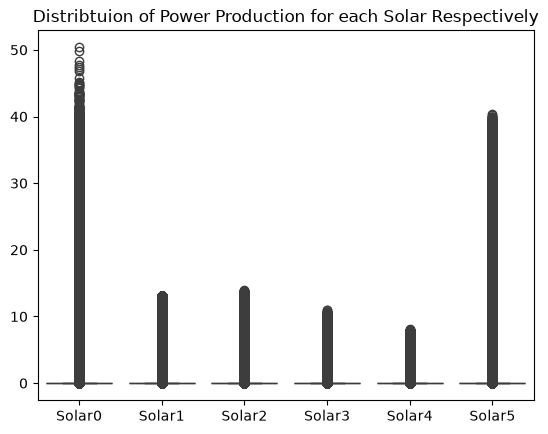

In [156]:
sns.boxplot(data = series_testing_dataset.iloc[:, 6:])
plt.title("Distribtuion of Power Production for each Solar Respectively");

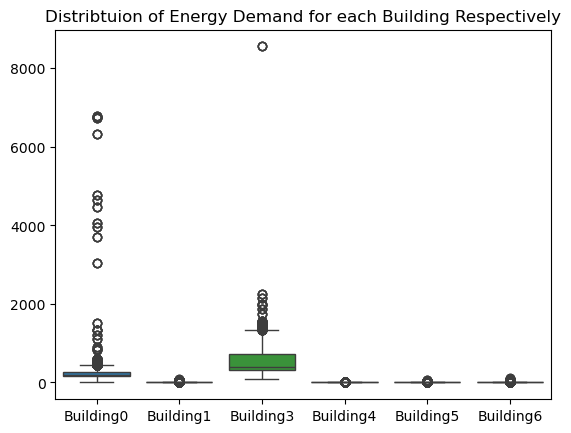

In [18]:
sns.boxplot(data = series_testing_dataset.iloc[:, :6])
plt.title("Distribtuion of Energy Demand for each Building Respectively");

Text(0.5, 1.0, 'Correlation of Buildings')

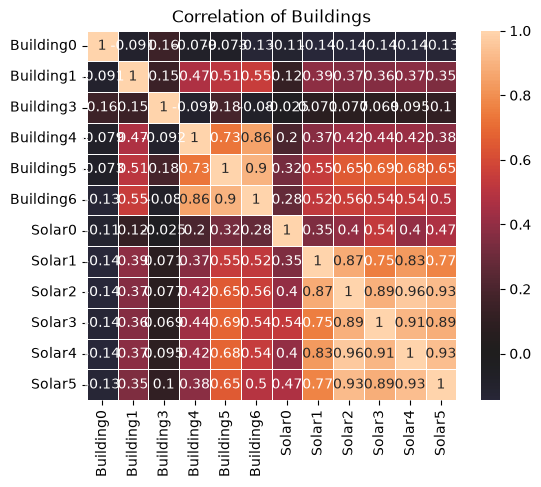

In [157]:
correlation = series_testing_dataset.corr()
sns.heatmap(correlation, annot = True, center = 0, square = True, linewidth = .5);
plt.title("Correlation of Buildings")

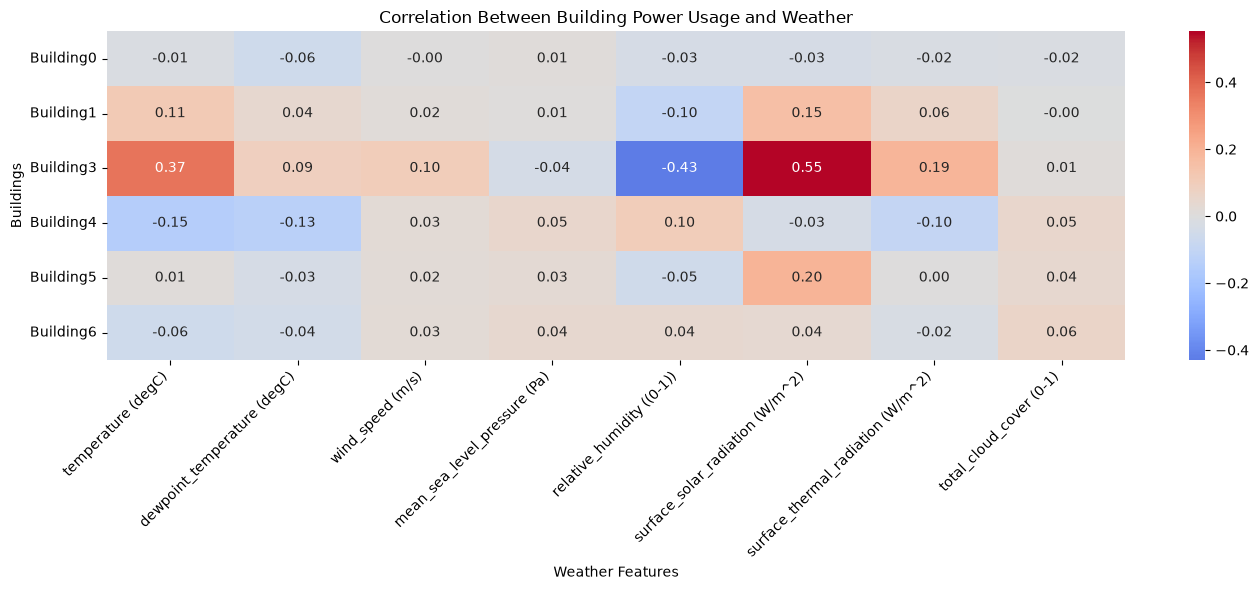

In [169]:
resample = series_testing_dataset.resample("h").mean()
combined = resample.join(New_Weatherset, how = "inner")
building_cols = [
    "Building0",
    "Building1",
    "Building3",
    "Building4",
    "Building5",
    "Building6"
]

weather_cols = [
    "temperature (degC)",
    "dewpoint_temperature (degC)",
    "wind_speed (m/s)",
    "mean_sea_level_pressure (Pa)",
    "relative_humidity ((0-1))",
    "surface_solar_radiation (W/m^2)",
    "surface_thermal_radiation (W/m^2)",
    "total_cloud_cover (0-1)"
]

corr = combined[building_cols + weather_cols].corr()

building_weather_corr = corr.loc[
    building_cols,
    weather_cols
]

plt.figure(figsize=(14, 6))

sns.heatmap(
    building_weather_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Building Power Usage and Weather")
plt.xlabel("Weather Features")
plt.ylabel("Buildings")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Building0 Power Usage Series')

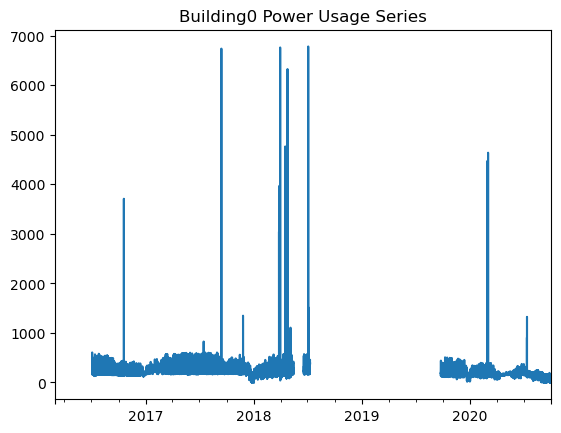

In [24]:
series_testing_dataset["Building0"].plot();
plt.title("Building0 Power Usage Series")

In [32]:
not_nan = True

for idx, item in series_testing_dataset["Building0"].items():
    if not_nan:
        if pd.isna(item):
            print("First NaN at:", idx)
            not_nan = False
    else:
        if not pd.isna(item):
            print("First non-NaN at:", idx)
            not_nan = True

First NaN at: 2016-03-01 04:15:00
First non-NaN at: 2016-07-03 21:30:00
First NaN at: 2016-10-18 15:15:00
First non-NaN at: 2016-10-18 21:30:00
First NaN at: 2017-09-12 16:15:00
First non-NaN at: 2017-09-13 03:45:00
First NaN at: 2017-11-14 15:15:00
First non-NaN at: 2017-11-14 20:00:00
First NaN at: 2017-11-14 20:15:00
First non-NaN at: 2017-11-14 22:15:00
First NaN at: 2017-11-25 02:30:00
First non-NaN at: 2017-11-25 06:15:00
First NaN at: 2017-12-26 01:15:00
First non-NaN at: 2017-12-26 02:15:00
First NaN at: 2017-12-31 01:15:00
First non-NaN at: 2017-12-31 06:15:00
First NaN at: 2018-01-01 02:15:00
First non-NaN at: 2018-01-01 06:15:00
First NaN at: 2018-03-21 04:30:00
First non-NaN at: 2018-03-21 04:45:00
First NaN at: 2018-03-26 05:30:00
First non-NaN at: 2018-03-26 16:15:00
First NaN at: 2018-03-27 16:15:00
First non-NaN at: 2018-03-28 08:30:00
First NaN at: 2018-03-29 06:30:00
First non-NaN at: 2018-03-30 16:45:00
First NaN at: 2018-04-04 06:15:00
First non-NaN at: 2018-04-06 0

Text(0.5, 1.0, 'Building1 Power Usage Series')

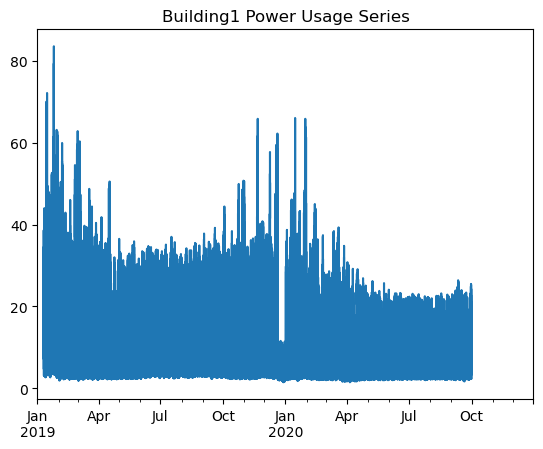

In [44]:
series_testing_dataset["Building1"].plot().set_xlim(pd.Timestamp("2019-01-01"),pd.Timestamp("2020-12-31"));
plt.title("Building1 Power Usage Series")

Text(0.5, 1.0, 'Building3 Power Usage Series')

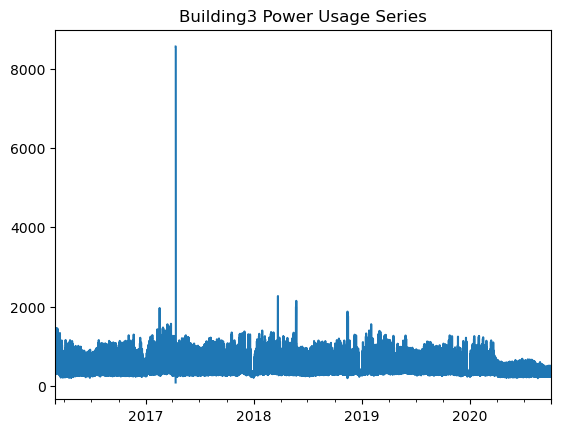

In [38]:
series_testing_dataset["Building3"].plot();
plt.title("Building3 Power Usage Series")

Text(0.5, 1.0, 'Building4 Power Usage Series')

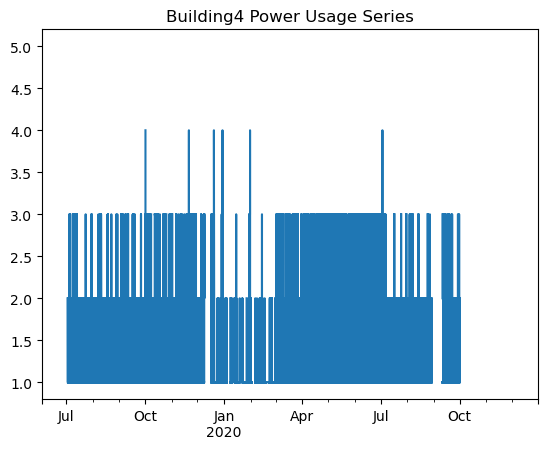

In [50]:
series_testing_dataset["Building4"].plot().set_xlim(pd.Timestamp("2019-06-03"),pd.Timestamp("2020-12-31"));
plt.title("Building4 Power Usage Series")

In [13]:
not_nan = True
first_nan = None

for idx, item in series_testing_dataset["Building4"].items():
    if not_nan:
        if pd.isna(item):
            first_nan = idx
            not_nan = False
    else:
        if not pd.isna(item):
            if idx - first_nan > pd.Timedelta("1 hour"):
                print('Start Nan at:', first_nan )
                print("Final non-NaN at:", idx)
                not_nan = True
                first_nan = None
            not_nan = True

Start Nan at: 2019-07-10 02:15:00
Final non-NaN at: 2019-07-10 03:45:00
Start Nan at: 2019-07-10 04:00:00
Final non-NaN at: 2019-07-10 05:15:00
Start Nan at: 2019-07-10 05:30:00
Final non-NaN at: 2019-07-10 07:15:00
Start Nan at: 2019-07-10 07:30:00
Final non-NaN at: 2019-07-10 09:15:00
Start Nan at: 2019-07-10 09:30:00
Final non-NaN at: 2019-07-10 11:15:00
Start Nan at: 2019-07-10 11:30:00
Final non-NaN at: 2019-07-10 13:00:00
Start Nan at: 2019-07-10 13:15:00
Final non-NaN at: 2019-07-10 14:45:00
Start Nan at: 2019-07-10 15:00:00
Final non-NaN at: 2019-07-10 16:30:00
Start Nan at: 2019-07-10 16:45:00
Final non-NaN at: 2019-07-10 18:00:00
Start Nan at: 2019-07-10 18:15:00
Final non-NaN at: 2019-07-10 19:45:00
Start Nan at: 2019-07-10 20:00:00
Final non-NaN at: 2019-07-10 21:45:00
Start Nan at: 2019-08-24 05:15:00
Final non-NaN at: 2019-08-24 06:30:00
Start Nan at: 2019-08-24 06:45:00
Final non-NaN at: 2019-08-24 08:00:00
Start Nan at: 2019-08-31 05:30:00
Final non-NaN at: 2019-08-31 0

Text(0.5, 1.0, 'Building5 Power Usage Series')

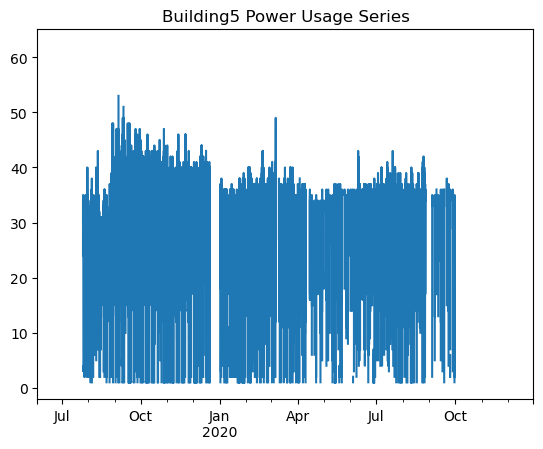

In [52]:
series_testing_dataset["Building5"].plot().set_xlim(pd.Timestamp("2019-06-03"),pd.Timestamp("2020-12-31"));
plt.title("Building5 Power Usage Series")

Text(0.5, 1.0, 'Building6 Power Usage Series')

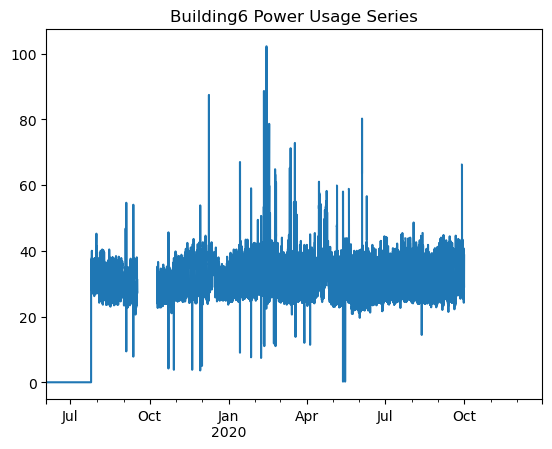

In [ ]:
series_testing_dataset["Building6"].plot().set_xlim(pd.Timestamp("2019-06-03"),pd.Timestamp("2020-12-31"));
plt.title("Building6 Power Usage Series") 	

In [16]:
not_nan = True
first_nan = None

for idx, item in series_testing_dataset["Building6"].items():
    if not_nan:
        if pd.isna(item):
            first_nan = idx
            not_nan = False
    else:
        if not pd.isna(item):
            if idx - first_nan > pd.Timedelta("1 hour"):
                print('Start Nan at:', first_nan )
                print("Final non-NaN at:", idx)
                not_nan = True
                first_nan = None
            not_nan = True

Start Nan at: 2019-09-16 16:00:00
Final non-NaN at: 2019-10-09 19:45:00


# Weather Data Analysis and Outliers

In [ ]:
Building_Weather_correlation = series_testing_dataset.corr

Text(0.5, 1.0, 'Correlation of Weather Features')

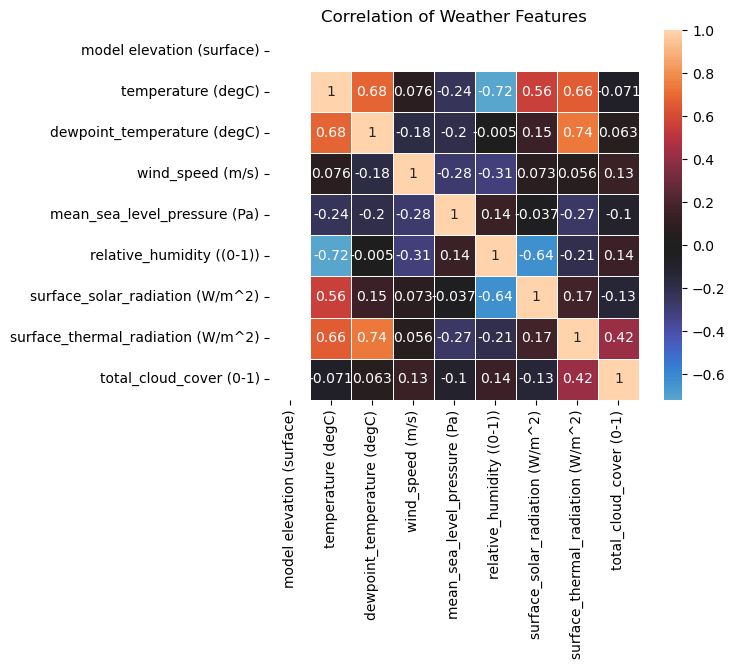

In [222]:
correlation = New_Weatherset.corr()
sns.heatmap(correlation, annot = True, center = 0, square = True, linewidth = .5);
plt.title("Correlation of Weather Features")

# DataFrames for Building Training Sets

### Building0 Dataset

In [5]:
Building0_Dataset = pd.concat([series_testing_dataset.loc["2016-07-03 21:30:00" : "2018-05-14 18:30:00", "Building0"],
                               series_testing_dataset.loc["2019-09-24 00:15:00": "2020-09-30 23:45:00", "Building0"]])
Building0_Dataset

2016-07-03 21:30:00    283.8
2016-07-03 21:45:00    283.8
2016-07-03 22:00:00    283.8
2016-07-03 22:15:00    606.0
2016-07-03 22:30:00    606.0
                       ...  
2020-09-30 22:45:00     96.9
2020-09-30 23:00:00     96.9
2020-09-30 23:15:00     37.4
2020-09-30 23:30:00     37.4
2020-09-30 23:45:00     37.4
Name: Building0, Length: 101076, dtype: float64

### Building1 Dataset

In [6]:
Building1_Dataset = series_testing_dataset.loc["2019-01-09 23:15:00" :"2020-09-30 23:45:00", "Building1"]

Building1_Dataset

2019-01-09 23:15:00     8.1
2019-01-09 23:30:00    15.7
2019-01-09 23:45:00    22.8
2019-01-10 00:00:00    32.7
2019-01-10 00:15:00     8.1
                       ... 
2020-09-30 22:45:00    14.4
2020-09-30 23:00:00    18.8
2020-09-30 23:15:00     4.5
2020-09-30 23:30:00     9.6
2020-09-30 23:45:00    14.0
Freq: 15min, Name: Building1, Length: 60483, dtype: float64

### Building3 Dataset

In [10]:
Building3_Dataset = series_testing_dataset.loc["2017-01-01 00:00:00" : "2020-09-30 23:45:00", "Building3"]

Building3_Dataset

2017-01-01 00:00:00    310.0
2017-01-01 00:15:00    331.0
2017-01-01 00:30:00    331.0
2017-01-01 00:45:00    331.0
2017-01-01 01:00:00    331.0
                       ...  
2020-09-30 22:45:00    389.0
2020-09-30 23:00:00    389.0
2020-09-30 23:15:00    415.0
2020-09-30 23:30:00    415.0
2020-09-30 23:45:00    415.0
Freq: 15min, Name: Building3, Length: 131424, dtype: float64

### Building4 Dataset

In [25]:
Building4_Dataset = series_testing_dataset.loc["2019-07-03 04:45:00" : "2020-09-30 23:45:00", "Building4"]

Building4_Dataset

2019-07-03 04:45:00    2.0
2019-07-03 05:00:00    NaN
2019-07-03 05:15:00    1.0
2019-07-03 05:30:00    2.0
2019-07-03 05:45:00    NaN
                      ... 
2020-09-30 22:45:00    NaN
2020-09-30 23:00:00    1.0
2020-09-30 23:15:00    NaN
2020-09-30 23:30:00    NaN
2020-09-30 23:45:00    NaN
Freq: 15min, Name: Building4, Length: 43757, dtype: float64

### Building6 Dataset

In [26]:
Building6_Dataset = pd.concat([series_testing_dataset.loc["2019-07-25 01:45:00":"2019-09-16 16:00:00", "Building6"],
                               series_testing_dataset.loc["2019-10-09 19:45:00": "2020-09-30 23:45:00", "Building6"]])
Building6_Dataset

2019-07-25 01:45:00    36.8
2019-07-25 02:00:00    34.6
2019-07-25 02:15:00    34.6
2019-07-25 02:30:00    36.2
2019-07-25 02:45:00    36.2
                       ... 
2020-09-30 22:45:00    35.6
2020-09-30 23:00:00    38.6
2020-09-30 23:15:00    38.6
2020-09-30 23:30:00    38.6
2020-09-30 23:45:00    38.6
Name: Building6, Length: 39435, dtype: float64

# Feature Dataset for Building Power Usage
The feature dataset ERA5 Weather report provided to us gives insight into the solar panel power production. However, it doesn't provide any usefulness in prediciting Building Power Usage. Thus, we have compiled various information about Monash University which would be applicable to building power usage.


In [27]:
import pandas as pd 

index = pd.date_range(start="2016-01-01 00:00:00", end="2020-09-30 23:59:45", freq="15min")
Feature_dataset = pd.DataFrame(index = index)


import pandas as pd
import numpy as np

# ============================================================
# 0. PREPARE DATETIME INDEX
# ============================================================

Feature_dataset.index = pd.to_datetime(Feature_dataset.index)
Feature_dataset = Feature_dataset.sort_index()

date = Feature_dataset.index.normalize()
hour = Feature_dataset.index.hour
minute = Feature_dataset.index.minute
time_minutes = hour * 60 + minute


# ============================================================
# 1. HELPER FUNCTION FOR DATE RANGES
# ============================================================

def in_date_ranges(index, ranges):
    dates = index.normalize()
    mask = pd.Series(False, index=index)

    for start, end in ranges:
        start = pd.Timestamp(start)
        end = pd.Timestamp(end)

        mask |= (dates >= start) & (dates <= end)

    return mask.astype(int).values


# ============================================================
# 2. WEEKDAY / WEEKEND
# ============================================================

Feature_dataset["is_weekday"] = (
    Feature_dataset.index.dayofweek < 5
).astype(int)

Feature_dataset["is_weekend"] = (
    Feature_dataset.index.dayofweek >= 5
).astype(int)


# ============================================================
# 3. UNIVERSITY OPEN / CLOSED
# ============================================================

university_open_ranges = [
    ("2016-01-04", "2016-12-22"),
    ("2017-01-03", "2017-12-21"),
    ("2018-01-02", "2018-12-21"),
    ("2019-01-02", "2019-12-23"),
    ("2020-01-02", "2020-12-23"),
]

Feature_dataset["university_open"] = in_date_ranges(
    Feature_dataset.index,
    university_open_ranges
)

Feature_dataset["university_closed"] = (
    1 - Feature_dataset["university_open"]
)


# ============================================================
# 4. CAMPUS FACILITY HOURS
# Mon-Fri: 09:00 - 17:00
# ============================================================

campus_time_open = (
    (time_minutes >= 9 * 60) &
    (time_minutes < 17 * 60)
)

Feature_dataset["campus_facility_hours"] = (
    (Feature_dataset["is_weekday"] == 1) &
    campus_time_open
).astype(int)


# ============================================================
# 5. LIBRARY OPENING HOURS
#
# Weekdays: 08:00 - 22:00
# Weekends: 10:00 - 17:00
# ============================================================

weekday_library = (
    (Feature_dataset["is_weekday"] == 1) &
    (time_minutes >= 8 * 60) &
    (time_minutes < 22 * 60)
)

weekend_library = (
    (Feature_dataset["is_weekend"] == 1) &
    (time_minutes >= 10 * 60) &
    (time_minutes < 17 * 60)
)

Feature_dataset["library_open_hours"] = (
    weekday_library | weekend_library
).astype(int)


# ============================================================
# 6. SEMESTER 1
# ============================================================

semester_1_ranges = [
    ("2016-02-29", "2016-05-27"),
    ("2017-02-21", "2017-05-26"),
    ("2018-02-26", "2018-05-25"),
    ("2019-03-04", "2019-05-31"),
    ("2020-03-09", "2020-06-12"),
]

Feature_dataset["semester_1"] = in_date_ranges(
    Feature_dataset.index,
    semester_1_ranges
)


# ============================================================
# 7. SEMESTER 2
# ============================================================

semester_2_ranges = [
    ("2016-07-25", "2016-10-21"),
    ("2017-07-24", "2017-10-20"),
    ("2018-07-23", "2018-10-19"),
    ("2019-07-29", "2019-10-25"),
    ("2020-08-03", "2020-11-06"),
]

Feature_dataset["semester_2"] = in_date_ranges(
    Feature_dataset.index,
    semester_2_ranges
)

Feature_dataset["semester_active"] = (
    (Feature_dataset["semester_1"] == 1) |
    (Feature_dataset["semester_2"] == 1)
).astype(int)


# ============================================================
# 8. MID-SEMESTER BREAK
# ============================================================

mid_sem_break_ranges = [
    ("2016-03-25", "2016-04-01"),
    ("2016-09-26", "2016-09-30"),

    ("2017-04-14", "2017-04-21"),
    ("2017-09-25", "2017-09-29"),

    ("2018-03-30", "2018-04-06"),
    ("2018-09-24", "2018-09-28"),

    ("2019-04-19", "2019-04-26"),
    ("2019-09-30", "2019-10-04"),

    ("2020-04-10", "2020-04-17"),
    ("2020-09-21", "2020-10-02"),
]

Feature_dataset["mid_sem_break"] = in_date_ranges(
    Feature_dataset.index,
    mid_sem_break_ranges
)


# ============================================================
# 9. ORIENTATION WEEK
# ============================================================

orientation_ranges = [
    ("2016-02-22", "2016-02-26"),
    ("2016-07-18", "2016-07-22"),

    ("2017-02-20", "2017-02-24"),
    ("2017-07-17", "2017-07-21"),

    ("2018-02-19", "2018-02-23"),
    ("2018-07-16", "2018-07-20"),

    ("2019-02-25", "2019-03-01"),
    ("2019-07-22", "2019-07-26"),

    # Semester 1 2020 not listed
    ("2020-07-27", "2020-07-31"),
]

Feature_dataset["orientation_week"] = in_date_ranges(
    Feature_dataset.index,
    orientation_ranges
)


# ============================================================
# 10. SWOT VAC
# ============================================================

swotvac_ranges = [
    ("2016-05-30", "2016-06-03"),
    ("2016-10-24", "2016-10-28"),

    ("2017-05-29", "2017-06-02"),
    ("2017-10-23", "2017-10-27"),

    ("2018-05-28", "2018-06-01"),
    ("2018-10-22", "2018-10-26"),

    ("2019-06-03", "2019-06-07"),
    ("2019-10-28", "2019-11-01"),

    ("2020-06-15", "2020-06-19"),
    ("2020-11-09", "2020-11-13"),
]

Feature_dataset["swotvac"] = in_date_ranges(
    Feature_dataset.index,
    swotvac_ranges
)


# ============================================================
# 11. EXAM PERIOD
# ============================================================

exam_ranges = [
    ("2016-06-06", "2016-06-24"),
    ("2016-10-31", "2016-11-18"),

    ("2017-06-05", "2017-06-23"),
    ("2017-10-30", "2017-11-17"),

    ("2018-06-04", "2018-06-22"),
    ("2018-10-29", "2018-11-16"),

    ("2019-06-10", "2019-06-28"),
    ("2019-11-04", "2019-11-22"),

    ("2020-06-22", "2020-07-10"),
    ("2020-11-16", "2020-12-04"),
]

Feature_dataset["exam_period"] = in_date_ranges(
    Feature_dataset.index,
    exam_ranges
)


# ============================================================
# 12. REMOTE EXAMS - 2020
# ============================================================

Feature_dataset["remote_exam"] = in_date_ranges(
    Feature_dataset.index,
    [("2020-06-22", "2020-07-10")]
)


# ============================================================
# 13. PUBLIC HOLIDAYS
# ============================================================

public_holidays = pd.to_datetime([

    # 2016
    "2016-01-26",
    "2016-03-25",
    "2016-03-28",
    "2016-03-29",
    "2016-04-25",
    "2016-09-30",
    "2016-12-25",
    "2016-12-26",

    # 2017
    "2017-01-26",
    "2017-04-14",
    "2017-04-17",
    "2017-04-18",
    "2017-04-25",
    "2017-09-29",
    "2017-12-25",
    "2017-12-26",

    # 2018
    "2018-01-01",
    "2018-01-26",
    "2018-03-30",
    "2018-04-02",
    "2018-04-03",
    "2018-04-25",
    "2018-09-28",
    "2018-12-25",
    "2018-12-26",

    # 2019
    "2019-01-01",
    "2019-01-28",
    "2019-04-19",
    "2019-04-22",
    "2019-04-23",
    "2019-04-25",
    "2019-09-27",
    "2019-12-25",
    "2019-12-26",

    # 2020
    "2020-01-01",
    "2020-01-27",
    "2020-04-10",
    "2020-04-13",
    "2020-04-14",
    "2020-04-25",
    "2020-10-23",
    "2020-12-25",
    "2020-12-28",
])

Feature_dataset["public_holiday"] = (
    date.isin(public_holidays)
).astype(int)


# ============================================================
# 14. COVID DISRUPTION
# 9 March 2020 onward
# ============================================================

Feature_dataset["covid_disruption"] = (
    date >= pd.Timestamp("2020-03-09")
).astype(int)


# ============================================================
# 15. ONLINE CLASSES
# 9 - 13 March 2020
# ============================================================

Feature_dataset["online_classes"] = in_date_ranges(
    Feature_dataset.index,
    [("2020-03-09", "2020-03-13")]
)


# ============================================================
# 16. COVID CAMPUS RESTRICTIONS
# 16 March - 18 October 2020
# ============================================================


Feature_dataset["covid_restrictions"] = in_date_ranges(
    Feature_dataset.index,
    [("2020-03-16", "2020-11-30")]
)

# Partial easing of Melbourne restrictions from 19 October
Feature_dataset["covid_oct_easing"] = (
    date >= pd.Timestamp("2020-10-19")
).astype(int)


# ============================================================
# 17. COVID CURFEW PERIOD
# 2 August - 13 September 2020
# ============================================================

Feature_dataset["covid_curfew_period"] = in_date_ranges(
    Feature_dataset.index,
    [("2020-08-02", "2020-09-13")]
)


# ============================================================
# 18. EFFECTIVE CAMPUS OPEN
#
# Combines:
# - University open
# - Weekday
# - 9am-5pm
# - Not public holiday
# - Not COVID restricted
# ============================================================

Feature_dataset["campus_facility_effectively_open"] = (
    (Feature_dataset["university_open"] == 1) &
    (Feature_dataset["is_weekday"] == 1) &
    campus_time_open &
    (Feature_dataset["public_holiday"] == 0) &
    (Feature_dataset["covid_restrictions"] == 0)
).astype(int)


# ============================================================
# 19. EFFECTIVE LIBRARY OPEN
# ============================================================

Feature_dataset["library_effectively_open"] = (
    (Feature_dataset["library_open_hours"] == 1) &
    (Feature_dataset["university_open"] == 1) &
    (Feature_dataset["public_holiday"] == 0) &
    (Feature_dataset["covid_restrictions"] == 0)
).astype(int)


# ============================================================
# 20. TEACHING DAY
# ============================================================

Feature_dataset["teaching_day"] = (
    (Feature_dataset["semester_active"] == 1) &
    (Feature_dataset["is_weekday"] == 1) &
    (Feature_dataset["mid_sem_break"] == 0) &
    (Feature_dataset["public_holiday"] == 0)
).astype(int)


# ============================================================
# 21. CHECK THE CREATED FEATURES
# ============================================================

feature_columns = [
    "is_weekday",
    "is_weekend",
    "university_open",
    "university_closed",
    "campus_facility_hours",
    "library_open_hours",
    "semester_1",
    "semester_2",
    "semester_active",
    "mid_sem_break",
    "orientation_week",
    "swotvac",
    "exam_period",
    "remote_exam",
    "public_holiday",
    "covid_disruption",
    "online_classes",
    "covid_restrictions",
    "covid_oct_easing",
    "covid_curfew_period",
    "campus_facility_effectively_open",
    "library_effectively_open",
    "teaching_day",
]

print(Feature_dataset[feature_columns].head())
print("\nFeature counts:")
print(Feature_dataset[feature_columns].sum())


                     is_weekday  is_weekend  university_open  \
2016-01-01 00:00:00           1           0                0   
2016-01-01 00:15:00           1           0                0   
2016-01-01 00:30:00           1           0                0   
2016-01-01 00:45:00           1           0                0   
2016-01-01 01:00:00           1           0                0   

                     university_closed  campus_facility_hours  \
2016-01-01 00:00:00                  1                      0   
2016-01-01 00:15:00                  1                      0   
2016-01-01 00:30:00                  1                      0   
2016-01-01 00:45:00                  1                      0   
2016-01-01 01:00:00                  1                      0   

                     library_open_hours  semester_1  semester_2  \
2016-01-01 00:00:00                   0           0           0   
2016-01-01 00:15:00                   0           0           0   
2016-01-01 00:30:00    

# Concantonating Feature Dataset for Buildings 0 & 1

### Building 0 Concantonate

In [28]:
features_for_building0 = pd.concat([
    Feature_dataset.loc["2016-07-03 21:30:00":"2018-05-14 18:30:00"],
    Feature_dataset.loc["2019-09-24 00:15:00":"2020-09-30 23:45:00"]
])
Building_0_feature = pd.concat([Building0_Dataset, features_for_building0],axis =1)



Building_0_feature

,Building0,is_weekday,is_weekend,university_open,university_closed,campus_facility_hours,library_open_hours,semester_1,semester_2,semester_active,...,remote_exam,public_holiday,covid_disruption,online_classes,covid_restrictions,covid_oct_easing,covid_curfew_period,campus_facility_effectively_open,library_effectively_open,teaching_day
2016-07-03 21:30:00,283.8,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016-07-03 21:45:00,283.8,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016-07-03 22:00:00,283.8,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016-07-03 22:15:00,606.0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016-07-03 22:30:00,606.0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-30 22:45:00,96.9,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:00:00,96.9,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:15:00,37.4,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:30:00,37.4,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0


### Building1 Concantonate

In [29]:
features_for_building1 = Feature_dataset.loc["2019-01-09 23:15:00" :"2020-09-30 23:45:00"]

Building_1_feature = pd.concat([Building1_Dataset, features_for_building1],axis =1)

Building_1_feature

,Building1,is_weekday,is_weekend,university_open,university_closed,campus_facility_hours,library_open_hours,semester_1,semester_2,semester_active,...,remote_exam,public_holiday,covid_disruption,online_classes,covid_restrictions,covid_oct_easing,covid_curfew_period,campus_facility_effectively_open,library_effectively_open,teaching_day
2019-01-09 23:15:00,8.1,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2019-01-09 23:30:00,15.7,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2019-01-09 23:45:00,22.8,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2019-01-10 00:00:00,32.7,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2019-01-10 00:15:00,8.1,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-30 22:45:00,14.4,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:00:00,18.8,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:15:00,4.5,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-09-30 23:30:00,9.6,1,0,1,0,0,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0


# Testing Data Normalisation

In [30]:
testingNov_dataset = convert_tsf_to_dataframe(r"/mnt/c/Users/alpay/Downloads/nov_data.tsf",replace_missing_vals_with="NaN",value_column_name="series_value")
testingNov_dataset = testingNov_dataset[0]
index = pd.date_range(start="2020-10-01 00:00:00", end="2020-10-31 23:45:00", freq = "15min")

new_headers = testingNov_dataset["series_name"].dropna().unique().tolist()

Nov_testing_dataset = pd.DataFrame(columns = new_headers,index = index)

for _, row in testingNov_dataset.iterrows():

    column = row.series_name
    series_start = pd.to_datetime(row.start_timestamp)
    start_time = "2020-10-01 00:00:00"
    wanted_start = pd.to_datetime("2020-10-01 00:00:00")
    wanted_end = pd.to_datetime("2020-10-31 23:45:00")
    values = row.series_value[int((wanted_start - series_start) / pd.Timedelta(minutes=15)):int((wanted_end - series_start) / pd.Timedelta(minutes=15))+1]

    start_time_index = Nov_testing_dataset.index.get_loc(start_time)

    Nov_testing_dataset.iloc[start_time_index:start_time_index + len(values),Nov_testing_dataset.columns.get_loc(column)] = values

Nov_testing_dataset = Nov_testing_dataset.apply(pd.to_numeric,errors='coerce')

Test_Building0 = Nov_testing_dataset["Building0"]
Testing_Building1 = Nov_testing_dataset["Building1"]


### TESTING FOR JUST NOVEMBER

In [171]:
testingNov_dataset = convert_tsf_to_dataframe(r"/mnt/c/Users/alpay/Downloads/nov_data.tsf",replace_missing_vals_with="NaN",value_column_name="series_value")
testingNov_dataset = testingNov_dataset[0]
index = pd.date_range(start="2020-10-01 00:00:00", end="2020-11-30 23:45:00", freq = "15min")

new_headers = testingNov_dataset["series_name"].dropna().unique().tolist()

Nov_testing_dataset = pd.DataFrame(columns = new_headers,index = index)

for _, row in testingNov_dataset.iterrows():

    column = row.series_name
    series_start = pd.to_datetime(row.start_timestamp)
    start_time = "2020-10-01 00:00:00"
    wanted_start = pd.to_datetime("2020-10-01 00:00:00")
    wanted_end = pd.to_datetime("2020-11-30 23:45:00")
    values = row.series_value[int((wanted_start - series_start) / pd.Timedelta(minutes=15)):int((wanted_end - series_start) / pd.Timedelta(minutes=15))+1]

    start_time_index = Nov_testing_dataset.index.get_loc(start_time)

    Nov_testing_dataset.iloc[start_time_index:start_time_index + len(values),Nov_testing_dataset.columns.get_loc(column)] = values

Nov_testing_dataset = Nov_testing_dataset.apply(pd.to_numeric,errors='coerce')

Test_Building0 = Nov_testing_dataset["Building0"]
Testing_Building1 = Nov_testing_dataset["Building1"]

In [32]:
# ============================================================
# OCTOBER - NOVEMBER 2020 TEST FEATURE DATASET
# ============================================================

Test_Feature_dataset = pd.DataFrame(
    index=pd.date_range(
        start="2020-10-01 00:00:00",
        end="2020-11-30 23:45:00",
        freq="15min"
    )
)

Test_Feature_dataset.index = pd.to_datetime(Test_Feature_dataset.index)
Test_Feature_dataset = Test_Feature_dataset.sort_index()

date = Test_Feature_dataset.index.normalize()
hour = Test_Feature_dataset.index.hour
minute = Test_Feature_dataset.index.minute
time_minutes = hour * 60 + minute


# ============================================================
# WEEKDAY / WEEKEND
# ============================================================

Test_Feature_dataset["is_weekday"] = (
    Test_Feature_dataset.index.dayofweek < 5
).astype(int)

Test_Feature_dataset["is_weekend"] = (
    Test_Feature_dataset.index.dayofweek >= 5
).astype(int)


# ============================================================
# UNIVERSITY OPEN / CLOSED
# ============================================================

Test_Feature_dataset["university_open"] = in_date_ranges(
    Test_Feature_dataset.index,
    university_open_ranges
)

Test_Feature_dataset["university_closed"] = (
    1 - Test_Feature_dataset["university_open"]
)


# ============================================================
# CAMPUS FACILITY HOURS
# ============================================================

campus_time_open = (
    (time_minutes >= 9 * 60) &
    (time_minutes < 17 * 60)
)

Test_Feature_dataset["campus_facility_hours"] = (
    (Test_Feature_dataset["is_weekday"] == 1) &
    campus_time_open
).astype(int)


# ============================================================
# LIBRARY OPENING HOURS
# ============================================================

weekday_library = (
    (Test_Feature_dataset["is_weekday"] == 1) &
    (time_minutes >= 8 * 60) &
    (time_minutes < 22 * 60)
)

weekend_library = (
    (Test_Feature_dataset["is_weekend"] == 1) &
    (time_minutes >= 10 * 60) &
    (time_minutes < 17 * 60)
)

Test_Feature_dataset["library_open_hours"] = (
    weekday_library | weekend_library
).astype(int)


# ============================================================
# SEMESTERS
# ============================================================

Test_Feature_dataset["semester_1"] = in_date_ranges(
    Test_Feature_dataset.index,
    semester_1_ranges
)

Test_Feature_dataset["semester_2"] = in_date_ranges(
    Test_Feature_dataset.index,
    semester_2_ranges
)

Test_Feature_dataset["semester_active"] = (
    (Test_Feature_dataset["semester_1"] == 1) |
    (Test_Feature_dataset["semester_2"] == 1)
).astype(int)


# ============================================================
# MID-SEMESTER BREAK
# ============================================================

Test_Feature_dataset["mid_sem_break"] = in_date_ranges(
    Test_Feature_dataset.index,
    mid_sem_break_ranges
)


# ============================================================
# ORIENTATION WEEK
# ============================================================

Test_Feature_dataset["orientation_week"] = in_date_ranges(
    Test_Feature_dataset.index,
    orientation_ranges
)


# ============================================================
# SWOTVAC
# ============================================================

Test_Feature_dataset["swotvac"] = in_date_ranges(
    Test_Feature_dataset.index,
    swotvac_ranges
)


# ============================================================
# EXAM PERIOD
# ============================================================

Test_Feature_dataset["exam_period"] = in_date_ranges(
    Test_Feature_dataset.index,
    exam_ranges
)


# ============================================================
# REMOTE EXAMS
# ============================================================

Test_Feature_dataset["remote_exam"] = in_date_ranges(
    Test_Feature_dataset.index,
    [("2020-06-22", "2020-07-10")]
)


# ============================================================
# PUBLIC HOLIDAY
# ============================================================

Test_Feature_dataset["public_holiday"] = (
    date.isin(public_holidays)
).astype(int)


# ============================================================
# COVID FEATURES
# ============================================================

# General COVID disruption
Test_Feature_dataset["covid_disruption"] = (
    date >= pd.Timestamp("2020-03-09")
).astype(int)

# Initial transition to online classes
Test_Feature_dataset["online_classes"] = in_date_ranges(
    Test_Feature_dataset.index,
    [("2020-03-09", "2020-03-13")]
)

# Restrictions affecting normal campus operations
# Do not assume restrictions ended on 18 October
Test_Feature_dataset["covid_restrictions"] = in_date_ranges(
    Test_Feature_dataset.index,
    [("2020-03-16", "2020-11-30")]
)

# Partial easing of Melbourne restrictions from 19 October
Test_Feature_dataset["covid_oct_easing"] = (
    date >= pd.Timestamp("2020-10-19")
).astype(int)

# Melbourne COVID curfew period
Test_Feature_dataset["covid_curfew_period"] = in_date_ranges(
    Test_Feature_dataset.index,
    [("2020-08-02", "2020-09-13")]
)

# ============================================================
# EFFECTIVE CAMPUS OPEN
# ============================================================

Test_Feature_dataset["campus_facility_effectively_open"] = (
    (Test_Feature_dataset["university_open"] == 1) &
    (Test_Feature_dataset["is_weekday"] == 1) &
    campus_time_open &
    (Test_Feature_dataset["public_holiday"] == 0) &
    (Test_Feature_dataset["covid_restrictions"] == 0)
).astype(int)


# ============================================================
# EFFECTIVE LIBRARY OPEN
# ============================================================

Test_Feature_dataset["library_effectively_open"] = (
    (Test_Feature_dataset["library_open_hours"] == 1) &
    (Test_Feature_dataset["university_open"] == 1) &
    (Test_Feature_dataset["public_holiday"] == 0) &
    (Test_Feature_dataset["covid_restrictions"] == 0)
).astype(int)


# ============================================================
# TEACHING DAY
# ============================================================

Test_Feature_dataset["teaching_day"] = (
    (Test_Feature_dataset["semester_active"] == 1) &
    (Test_Feature_dataset["is_weekday"] == 1) &
    (Test_Feature_dataset["mid_sem_break"] == 0) &
    (Test_Feature_dataset["public_holiday"] == 0)
).astype(int)


# Keep EXACTLY the same features/order as training
Test_Feature_dataset = Test_Feature_dataset[feature_columns]

Test_Feature_dataset

,is_weekday,is_weekend,university_open,university_closed,campus_facility_hours,library_open_hours,semester_1,semester_2,semester_active,mid_sem_break,...,remote_exam,public_holiday,covid_disruption,online_classes,covid_restrictions,covid_oct_easing,covid_curfew_period,campus_facility_effectively_open,library_effectively_open,teaching_day
2020-10-01 00:00:00,1,0,1,0,0,0,0,1,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-10-01 00:15:00,1,0,1,0,0,0,0,1,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-10-01 00:30:00,1,0,1,0,0,0,0,1,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-10-01 00:45:00,1,0,1,0,0,0,0,1,1,1,...,0,0,1,0,1,0,0,0,0,0
2020-10-01 01:00:00,1,0,1,0,0,0,0,1,1,1,...,0,0,1,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-11-30 22:45:00,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,1,0,0,0,0
2020-11-30 23:00:00,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,1,0,0,0,0
2020-11-30 23:15:00,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,1,0,0,0,0
2020-11-30 23:30:00,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,1,0,0,0,0


In [33]:
Nov_0_testing = pd.concat([Test_Building0, Test_Feature_dataset.loc["2020-10-01":"2020-10-31"]], axis=1)
Nov_1_testing = pd.concat([Testing_Building1, Test_Feature_dataset.loc["2020-10-01":"2020-10-31"]], axis=1)

### NOVEMBER

In [173]:

Nov_0_testing = pd.concat([Test_Building0, Test_Feature_dataset.loc["2020-10-01":"2020-11-30"]], axis=1)
Nov_1_testing = pd.concat([Testing_Building1, Test_Feature_dataset.loc["2020-10-01":"2020-11-30"]], axis=1)


Building_0_feature = pd.concat([
    Building_0_feature,
    Nov_0_testing.loc["2020-10-01":"2020-10-31"]
]).sort_index()

Building_1_feature = pd.concat([
    Building_1_feature,
    Nov_1_testing.loc["2020-10-01":"2020-10-31"]
]).sort_index()


Nov_0_testing = Nov_0_testing.loc["2020-11-01":].copy()
Nov_1_testing = Nov_1_testing.loc["2020-11-01":].copy()

In [34]:
Nov_0_testing = pd.concat([
    Nov_0_testing['Building0'].resample("1h").mean(),
    Nov_0_testing.iloc[:, 1:].resample("1h").last()
], axis=1)

Nov_1_testing = pd.concat([
    Nov_1_testing['Building1'].resample("1h").mean(),
    Nov_1_testing.iloc[:, 1:].resample("1h").last()
], axis=1)

Nov_0_testing["hour_sin"] = np.sin(
    2 * np.pi * Nov_0_testing.index.hour / 24
)

Nov_0_testing["hour_cos"] = np.cos(
    2 * np.pi * Nov_0_testing.index.hour / 24
)


Nov_1_testing["hour_sin"] = np.sin(
    2 * np.pi * Nov_1_testing.index.hour / 24
)

Nov_1_testing["hour_cos"] = np.cos(
    2 * np.pi * Nov_1_testing.index.hour / 24
)

day = Nov_1_testing.index.dayofweek

Nov_1_testing["day_sin"] = np.sin(2 * np.pi * day / 7)
Nov_1_testing["day_cos"] = np.cos(2 * np.pi * day / 7)



In [221]:
Nov_0_testing['Building0'] = (Nov_0_testing['Building0'] - Nov_0_testing['Building0'].mean()) / Nov_0_testing['Building0'].std()

Nov_1_testing['Building1'] = (Nov_1_testing['Building1'] - Nov_1_testing['Building1'].mean()) / Nov_1_testing['Building1'].std()






In [35]:
Nov_0_testing

,Building0,is_weekday,is_weekend,university_open,university_closed,campus_facility_hours,library_open_hours,semester_1,semester_2,semester_active,...,covid_disruption,online_classes,covid_restrictions,covid_oct_easing,covid_curfew_period,campus_facility_effectively_open,library_effectively_open,teaching_day,hour_sin,hour_cos
2020-10-01 00:00:00,20.300,1,0,1,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0.000000,1.000000
2020-10-01 01:00:00,4.400,1,0,1,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0.258819,0.965926
2020-10-01 02:00:00,4.600,1,0,1,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0.500000,0.866025
2020-10-01 03:00:00,11.650,1,0,1,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0.707107,0.707107
2020-10-01 04:00:00,9.475,1,0,1,0,0,0,0,1,1,...,1,0,1,0,0,0,0,0,0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-10-31 19:00:00,140.450,0,1,1,0,0,0,0,1,1,...,1,0,1,1,0,0,0,0,-0.965926,0.258819
2020-10-31 20:00:00,139.225,0,1,1,0,0,0,0,1,1,...,1,0,1,1,0,0,0,0,-0.866025,0.500000
2020-10-31 21:00:00,126.875,0,1,1,0,0,0,0,1,1,...,1,0,1,1,0,0,0,0,-0.707107,0.707107
2020-10-31 22:00:00,109.500,0,1,1,0,0,0,0,1,1,...,1,0,1,1,0,0,0,0,-0.500000,0.866025


# Resampling Data - Train Data

In [36]:
Building_0_feature = pd.concat([
    Building_0_feature['Building0'].resample("1h").mean(),
    Building_0_feature.iloc[:, 1:].resample("1h").last()
], axis=1)

Building_1_feature = pd.concat([
    Building_1_feature['Building1'].resample("1h").mean(),
    Building_1_feature.iloc[:, 1:].resample("1h").last()
], axis=1)

Building_0_feature["hour_sin"] = np.sin(
    2 * np.pi * Building_0_feature.index.hour / 24
)

Building_0_feature["hour_cos"] = np.cos(
    2 * np.pi * Building_0_feature.index.hour / 24
)


Building_1_feature["hour_sin"] = np.sin(
    2 * np.pi * Building_1_feature.index.hour / 24
)

Building_1_feature["hour_cos"] = np.cos(
    2 * np.pi * Building_1_feature.index.hour / 24
)

day = Building_1_feature.index.dayofweek

Building_1_feature["day_sin"] = np.sin(2 * np.pi * day / 7)
Building_1_feature["day_cos"] = np.cos(2 * np.pi * day / 7)



# Normalisation - Train Data

In [224]:
TRAIN_MEAN0 = Building_0_feature['Building0'].mean()
TRAIN_STD0 = Building_0_feature['Building0'].std()

Building_0_feature['Building0'] = (Building_0_feature['Building0'] - TRAIN_MEAN0) / TRAIN_STD0 if TRAIN_STD0 != 0 else Building_0_feature['Building0']

TRAIN_MEAN1 = Building_1_feature['Building1'].mean()
TRAIN_STD1 = Building_1_feature['Building1'].std()

Building_1_feature['Building1'] = (Building_1_feature['Building1'] - TRAIN_MEAN1) / TRAIN_STD1 if TRAIN_STD1 != 0 else Building_1_feature['Building1']


In [37]:
Building_0_feature

,Building0,is_weekday,is_weekend,university_open,university_closed,campus_facility_hours,library_open_hours,semester_1,semester_2,semester_active,...,covid_disruption,online_classes,covid_restrictions,covid_oct_easing,covid_curfew_period,campus_facility_effectively_open,library_effectively_open,teaching_day,hour_sin,hour_cos
2016-07-03 21:00:00,283.800,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.707107,0.707107
2016-07-03 22:00:00,525.450,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.500000,0.866025
2016-07-03 23:00:00,381.000,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.258819,0.965926
2016-07-04 00:00:00,314.850,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,1.000000
2016-07-04 01:00:00,305.050,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.258819,0.965926
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-30 19:00:00,155.075,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.965926,0.258819
2020-09-30 20:00:00,160.575,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.500000
2020-09-30 21:00:00,147.450,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.707107,0.707107
2020-09-30 22:00:00,108.350,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.500000,0.866025


# Modelling and Imputation

### Linear Regression

#### BUILDING 0 OCTOBER

In [19]:
from sklearn.linear_model import LinearRegression

Linear_Model = LinearRegression(fit_intercept = True)

X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

Linear_Model.fit(X_train, y_train)

y_pred = Linear_Model.predict(X_test)




In [20]:
optimal_gradient = Linear_Model.coef_[0]
optimal_intercept = Linear_Model.intercept_

print("Intercept:", Linear_Model.intercept_)

for feature, coefficient in zip(X_train.columns, Linear_Model.coef_):
    print(feature, "=", coefficient)

print("RMSE = {:.2f}".format(np.sqrt(np.mean((y_test - y_pred) ** 2))))
print("MAE = {:.2f}".format(np.mean(np.abs(y_test - y_pred))))
print("R^2 = {:.2f}".format(Linear_Model.score(X_test, y_test)))

Intercept: -0.48507662678016
is_weekday = 0.019702516326160883
is_weekend = -0.019702516326160907
university_open = 0.4144611991935692
university_closed = -0.41446119919356356
campus_facility_hours = -0.08226359100497456
library_open_hours = 0.4035166308413072
semester_1 = 0.6779997379342758
semester_2 = 0.6726859877161455
semester_active = -0.4919563637696126
mid_sem_break = -0.1671134654147682
orientation_week = 0.2658111049050545
swotvac = 0.2596682529876397
exam_period = 0.11248660281114248
remote_exam = 0.5649912292529498
public_holiday = -0.16521863982324075
covid_disruption = -0.6067893429167164
online_classes = 0.07650493163146517
covid_restrictions = -0.3170376484443184
covid_curfew_period = -0.16387298113736037
campus_facility_effectively_open = 0.49365775130615286
library_effectively_open = -0.4193802333414836
teaching_day = 0.1326439896791662
hour_sin = 0.18172211789925655
hour_cos = 0.019336811544062086
RMSE = 1.14
MAE = 0.81
R^2 = -0.29


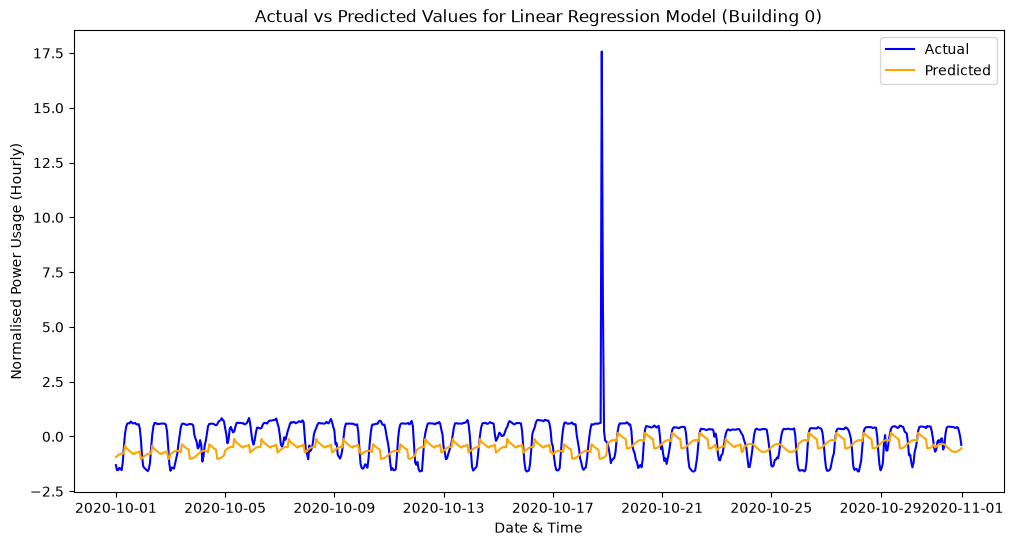

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Linear Regression Model (Building 0)")
plt.legend()
plt.show()

In [22]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))


Predictions within ±10% = 7.72%


### BUILDING 0 NOVEMBER

In [58]:
from sklearn.linear_model import LinearRegression

Linear_Model = LinearRegression(fit_intercept = True)

X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

Linear_Model.fit(X_train, y_train)

y_pred = Linear_Model.predict(X_test)




In [59]:
optimal_gradient = Linear_Model.coef_[0]
optimal_intercept = Linear_Model.intercept_

print("Intercept:", Linear_Model.intercept_)

for feature, coefficient in zip(X_train.columns, Linear_Model.coef_):
    print(feature, "=", coefficient)

print("RMSE = {:.2f}".format(np.sqrt(np.mean((y_test - y_pred) ** 2))))
print("MAE = {:.2f}".format(np.mean(np.abs(y_test - y_pred))))
print("R^2 = {:.2f}".format(Linear_Model.score(X_test, y_test)))

Intercept: -0.45289106468475937
is_weekday = 0.018448160443323217
is_weekend = -0.018448160443323425
university_open = 0.4152952793691859
university_closed = -0.4152952793691885
campus_facility_hours = -0.07442094579623403
library_open_hours = 0.4119056336436069
semester_1 = 0.7527805552642622
semester_2 = 0.6977615419223906
semester_active = -0.5359053484365166
mid_sem_break = -0.1683263209723412
orientation_week = 0.2699381548325944
swotvac = 0.26587059482043157
exam_period = 0.10860080249427956
remote_exam = 0.6151546788214838
public_holiday = -0.1719140079625819
covid_disruption = -1.324677995445536
online_classes = 0.7827094528498694
covid_restrictions = 0.346870492056817
covid_curfew_period = -0.08086677532520027
campus_facility_effectively_open = 0.4795843461704515
library_effectively_open = -0.42329715366881665
teaching_day = 0.11235472624578013
hour_sin = 0.17216605896376538
hour_cos = 0.017023640474260034
RMSE = 1.51
MAE = 1.33
R^2 = -1.28


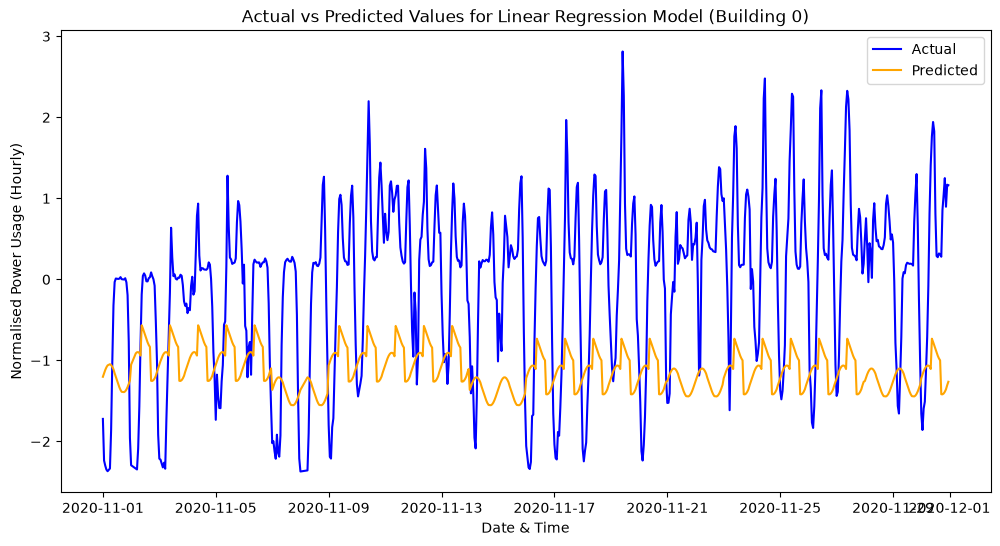

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Linear Regression Model (Building 0)")
plt.legend()
plt.show()

In [61]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))


Predictions within ±10% = 2.82%


#### BUILDING 1 OCTOBER

In [21]:
Linear_Model = LinearRegression(fit_intercept = True)

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

Linear_Model.fit(X_train, y_train)

y_pred = Linear_Model.predict(X_test)

In [22]:
optimal_gradient = Linear_Model.coef_[0]
optimal_intercept = Linear_Model.intercept_

print("Intercept:", Linear_Model.intercept_)

for feature, coefficient in zip(X_train.columns, Linear_Model.coef_):
    print(feature, "=", coefficient)

print("RMSE = {:.2f}".format(np.sqrt(np.mean((y_test - y_pred) ** 2))))
print("MAE = {:.2f}".format(np.mean(np.abs(y_test - y_pred))))
print("R^2 = {:.2f}".format(Linear_Model.score(X_test, y_test)))

Intercept: -0.10279271310500952
is_weekday = 0.5586894732615477
is_weekend = -0.5586894732615427
university_open = 0.705327939998698
university_closed = -0.7053279399986917
campus_facility_hours = -0.48848797642744757
library_open_hours = -0.298509154949693
semester_1 = -0.001625043169632039
semester_2 = 0.006406898312139194
semester_active = 0.004781855142509091
mid_sem_break = -0.2497722567378447
orientation_week = 0.043630586703830514
swotvac = -0.08580973289340527
exam_period = -0.15947109262207418
remote_exam = -0.10432972064731569
public_holiday = -0.49468816994669257
covid_disruption = -0.3568871376239582
online_classes = 0.38398058965684534
covid_restrictions = -0.41533056791593886
covid_curfew_period = -0.03451747761679096
campus_facility_effectively_open = -0.11996429864211855
library_effectively_open = -0.5103761749071184
teaching_day = -0.24775589348978128
hour_sin = 0.15637760311938706
hour_cos = 0.06782000262237353
day_sin = 0.2296470374385361
day_cos = -0.046998548725152

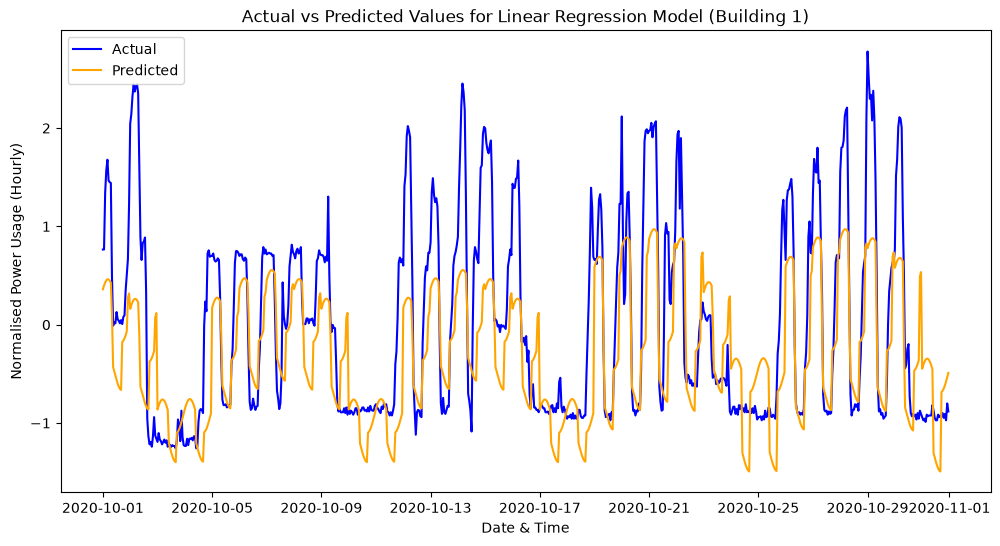

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Linear Regression Model (Building 1)")
plt.legend()
plt.show()

In [26]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 23.52%


### BUILDING 1 NOVEMBER


In [ ]:
Linear_Model = LinearRegression(fit_intercept = True)

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

Linear_Model.fit(X_train, y_train)

y_pred = Linear_Model.predict(X_test)

In [63]:
optimal_gradient = Linear_Model.coef_[0]
optimal_intercept = Linear_Model.intercept_

print("Intercept:", Linear_Model.intercept_)

for feature, coefficient in zip(X_train.columns, Linear_Model.coef_):
    print(feature, "=", coefficient)

print("RMSE = {:.2f}".format(np.sqrt(np.mean((y_test - y_pred) ** 2))))
print("MAE = {:.2f}".format(np.mean(np.abs(y_test - y_pred))))
print("R^2 = {:.2f}".format(Linear_Model.score(X_test, y_test)))

Intercept: -0.082816791369945
is_weekday = 0.5636570601217665
is_weekend = -0.5636570601217628
university_open = 0.7070483719828689
university_closed = -0.7070483719828612
campus_facility_hours = -0.48433440861748156
library_open_hours = -0.3043009788607709
semester_1 = 0.004966805673237737
semester_2 = 0.0098008924568172
semester_active = 0.014767698130055988
mid_sem_break = -0.25355323909971833
orientation_week = 0.04476125867941975
swotvac = -0.0864454758582054
exam_period = -0.16149931149020552
remote_exam = -0.10601121791684606
public_holiday = -0.5359964096798144
covid_disruption = -0.505881079109198
online_classes = 0.5380259140137741
covid_restrictions = -0.2726230007136486
covid_curfew_period = -0.03403005215924355
campus_facility_effectively_open = -0.12856170257806127
library_effectively_open = -0.50662002672773
teaching_day = -0.2716657026601301
hour_sin = 0.1529486326971497
hour_cos = 0.06654274299801236
day_sin = 0.23201067359430588
day_cos = -0.045886933248687437
RMSE = 

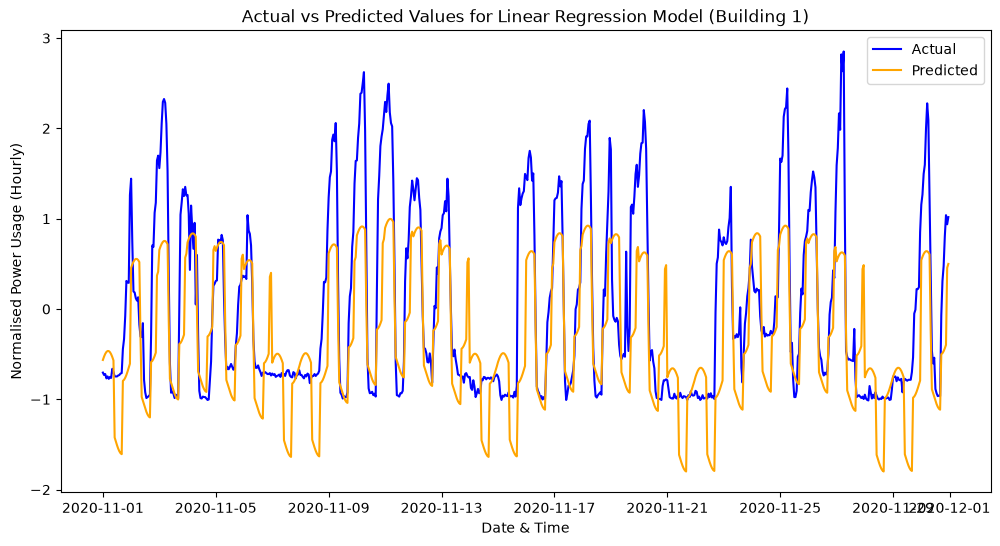

In [64]:
plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Linear Regression Model (Building 1)")
plt.legend()
plt.show()

In [65]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 18.61%


# Random Forest Regression

### Building 0 October

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestRegressor, VotingClassifier
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression # import the LogisticRegression model

import warnings


warnings.filterwarnings('ignore')


X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]



In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [40]:
cl = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_samples': [0.5, 0.75, 1.0],
    'max_depth': [None, 5, 10, 20]
}

tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=24 * 30)

grid_search = GridSearchCV(
    cl,
    param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
      n_jobs=-1
)

grid_search.fit(X_train, y_train)

cl = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_search.best_score_)
print(np.round(cv_rmse, 3))


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'max_depth': 10, 'max_samples': 0.5, 'n_estimators': 300}

Best CV RMSE:
45.254

Test results:
RMSE: 53.473
MAE: 23.237
R²: 0.405


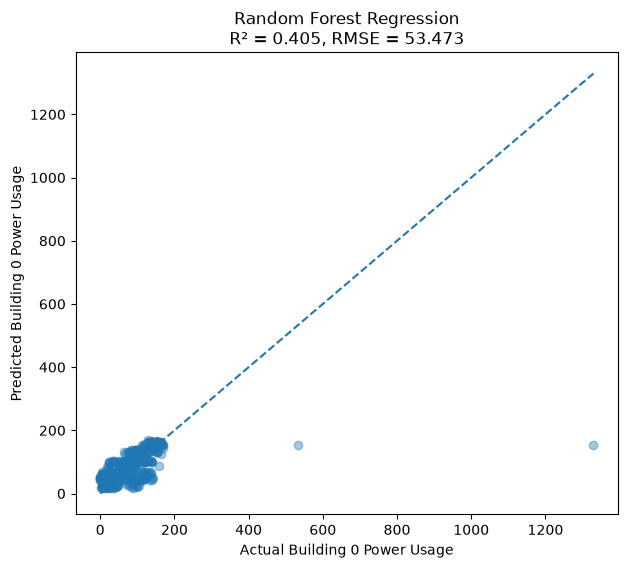

In [41]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building 0 Power Usage')
plt.ylabel('Predicted Building 0 Power Usage')

plt.title(
    'Random Forest Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

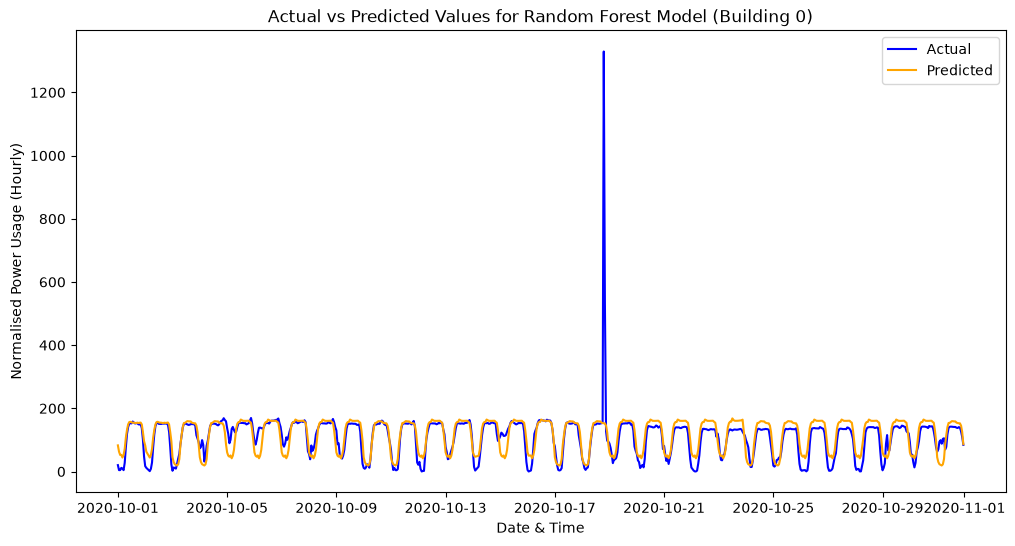

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Random Forest Model (Building 0)")
plt.legend()
plt.show()

In [46]:
Y_pred = cl.predict(X_test)

percentage_error = np.abs((y_test - Y_pred) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 38.35 %


### Building 0 November

In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestRegressor, VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression # import the LogisticRegression model

import warnings


warnings.filterwarnings('ignore')


X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]



In [157]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

cl = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_samples': [0.5, 0.75, 1.0],
    'max_depth': [None, 5, 10, 20]
}

grid_search = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
      n_jobs=-1
)

grid_search.fit(X_train, y_train)

cl = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_search.best_score_)
print(np.round(cv_rmse, 3))


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'max_depth': 5, 'max_samples': 0.5, 'n_estimators': 300}

Best CV RMSE:
89.979

Test results:
RMSE: 61.94
MAE: 44.691
R²: -0.088


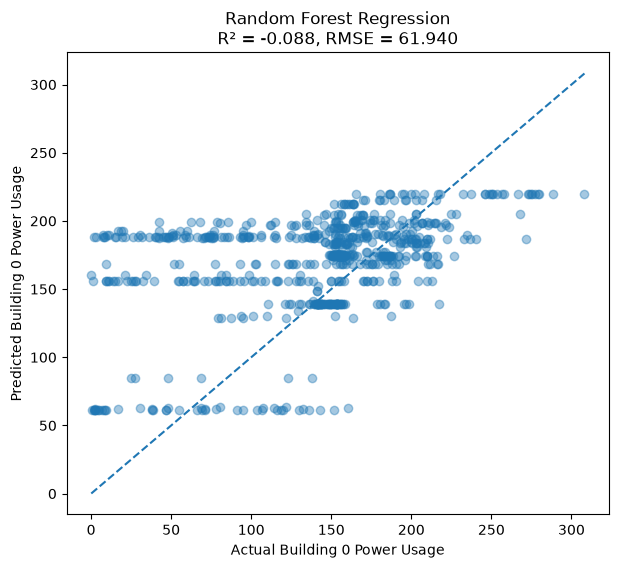

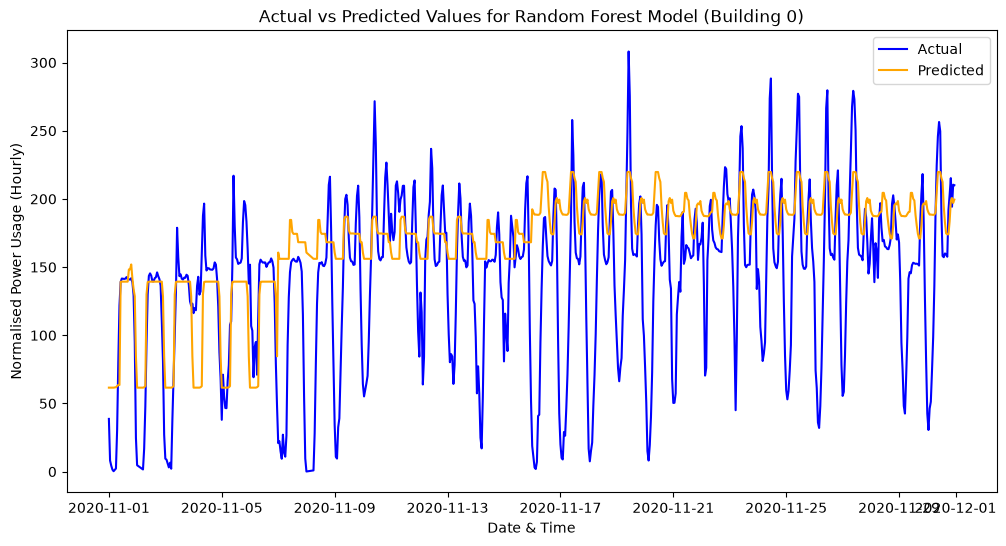

In [158]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building 0 Power Usage')
plt.ylabel('Predicted Building 0 Power Usage')

plt.title(
    'Random Forest Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Random Forest Model (Building 0)")
plt.legend()
plt.show()

In [159]:
Y_pred = cl.predict(X_test)

percentage_error = np.abs((y_test - Y_pred) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 27.75 %


### Building 1 October

In [47]:
X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [48]:
cl = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_samples': [0.5, 0.75, 1.0],
    'max_depth': [None, 5, 10, 20]
}

tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=24 * 30)

grid_search = GridSearchCV(
    cl,
    param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
      n_jobs=-1
)

grid_search.fit(X_train, y_train)

cl = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_search.best_score_)
print(np.round(cv_rmse, 3))


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'max_depth': 10, 'max_samples': 0.5, 'n_estimators': 300}

Best CV RMSE:
1.372

Test results:
RMSE: 1.49
MAE: 1.005
R²: 0.763


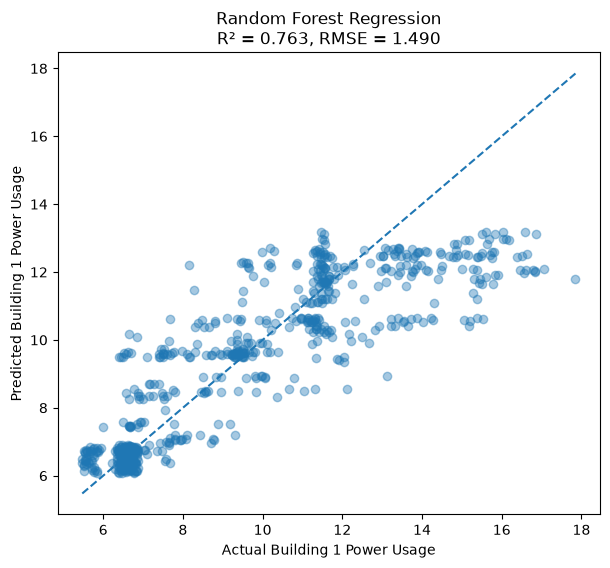

In [49]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building 1 Power Usage')
plt.ylabel('Predicted Building 1 Power Usage')

plt.title(
    'Random Forest Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

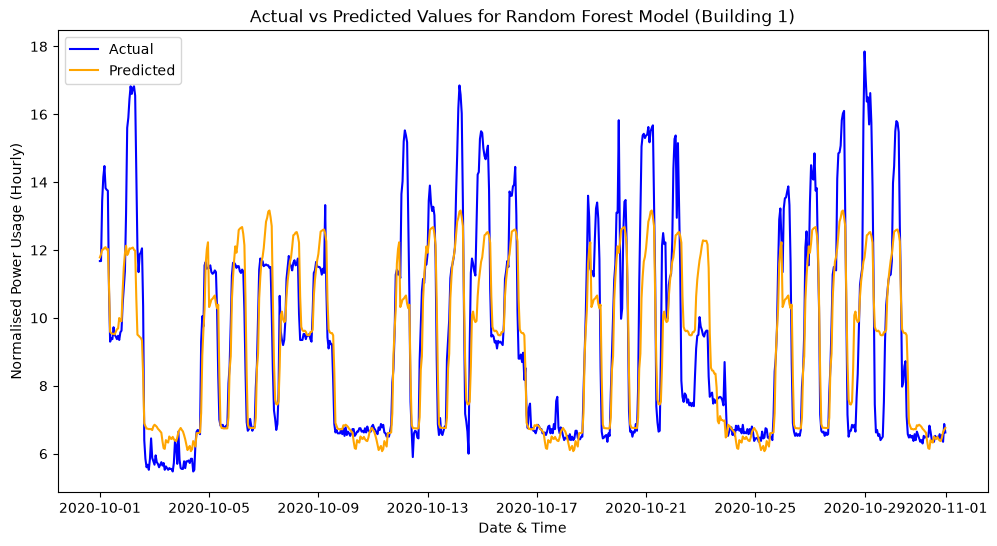

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Random Forest Model (Building 1)")
plt.legend()
plt.show()

In [51]:
Y_pred = cl.predict(X_test)

percentage_error = np.abs((y_test - Y_pred) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 62.1 %


### Building 1 November

In [160]:
X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [161]:
cl = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_samples': [0.5, 0.75, 1.0],
    'max_depth': [None, 5, 10, 20]
}

grid_search = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
      n_jobs=-1
)

grid_search.fit(X_train, y_train)

cl = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_search.best_score_)
print(np.round(cv_rmse, 3))


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'max_depth': 10, 'max_samples': 0.5, 'n_estimators': 200}

Best CV RMSE:
3.013

Test results:
RMSE: 2.914
MAE: 2.162
R²: 0.616


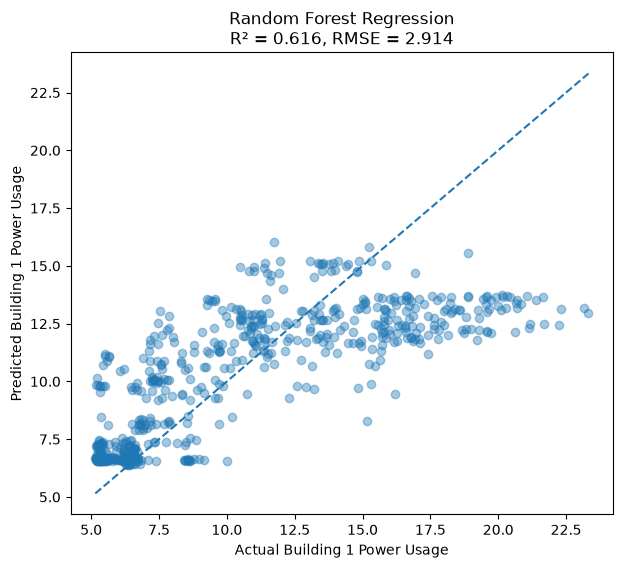

In [162]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building 1 Power Usage')
plt.ylabel('Predicted Building 1 Power Usage')

plt.title(
    'Random Forest Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

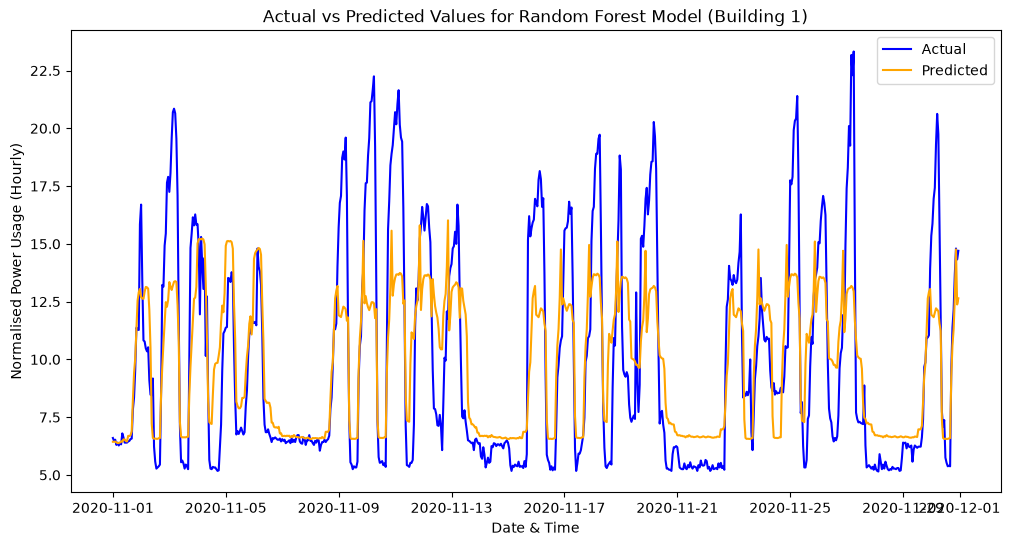

Within 10% accuracy: 27.36 %


In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for Random Forest Model (Building 1)")
plt.legend()
plt.show()

Y_pred = cl.predict(X_test)

percentage_error = np.abs((y_test - Y_pred) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

# KNN (Nearest Neighbours)

### Building 0 OCTOBER


In [27]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [28]:
cl = KNeighborsRegressor()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best parameters:")
print(grid_knn.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_knn.best_score_)
print(np.round(cv_rmse, 3))

cl = grid_knn.best_estimator_


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'n_neighbors': 20, 'p': 2, 'weights': 'uniform'}

Best CV RMSE:
0.828

Test results:
RMSE: 1.38
MAE: 1.092
R²: -0.906


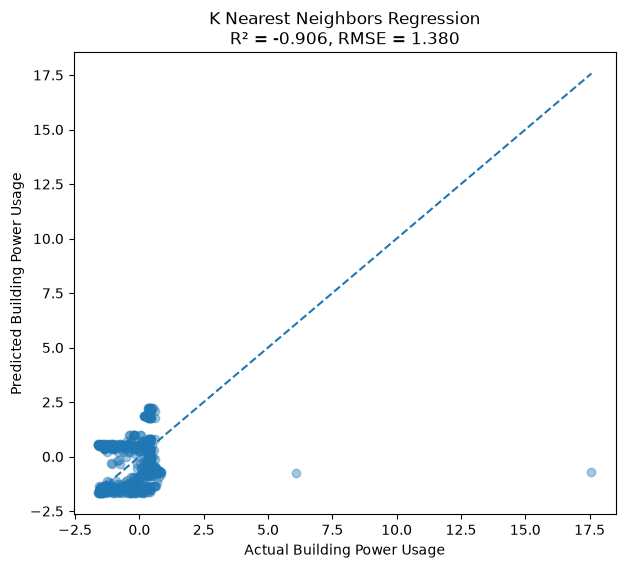

In [29]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building Power Usage')
plt.ylabel('Predicted Building Power Usage')

plt.title(
    'K Nearest Neighbors Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

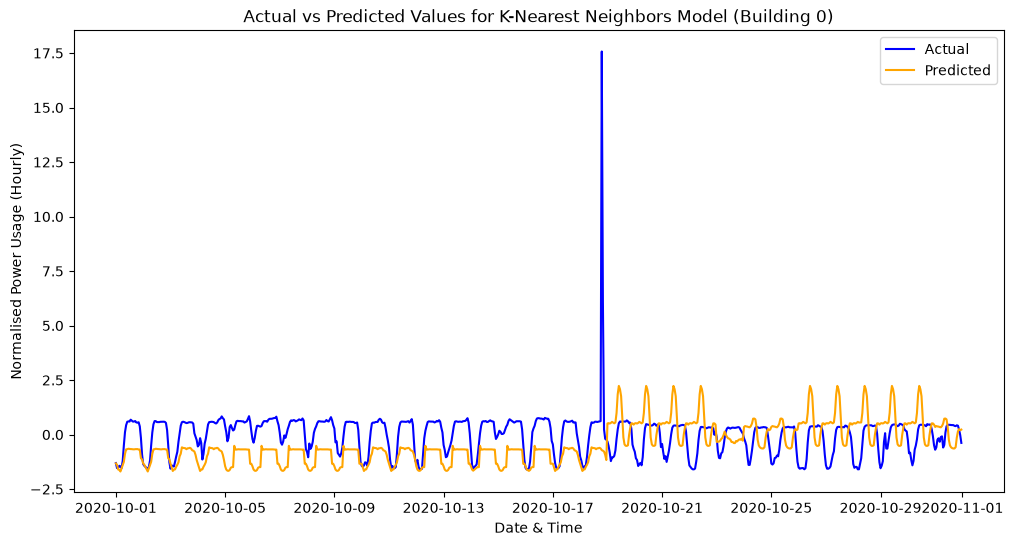

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for K-Nearest Neighbors Model (Building 0)")
plt.legend()
plt.show()

In [32]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (Y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 4.07%


### Building 0 November

In [66]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [67]:
cl = KNeighborsRegressor()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best parameters:")
print(grid_knn.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_knn.best_score_)
print(np.round(cv_rmse, 3))

cl = grid_knn.best_estimator_


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'n_neighbors': 20, 'p': 2, 'weights': 'uniform'}

Best CV RMSE:
0.851

Test results:
RMSE: 1.037
MAE: 0.865
R²: -0.078


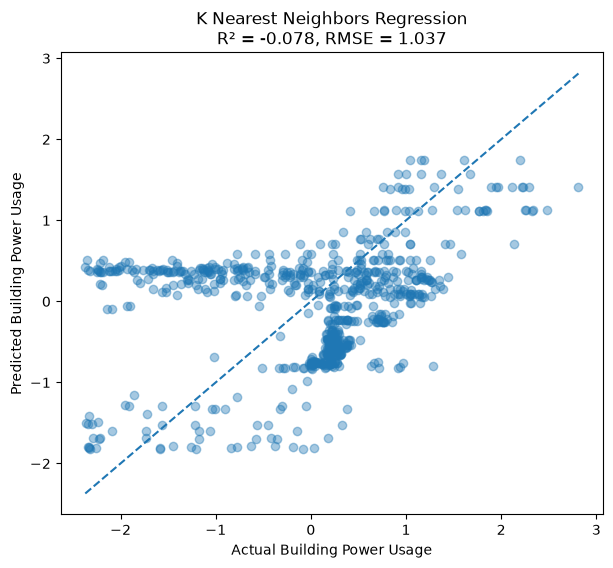

In [68]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building Power Usage')
plt.ylabel('Predicted Building Power Usage')

plt.title(
    'K Nearest Neighbors Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

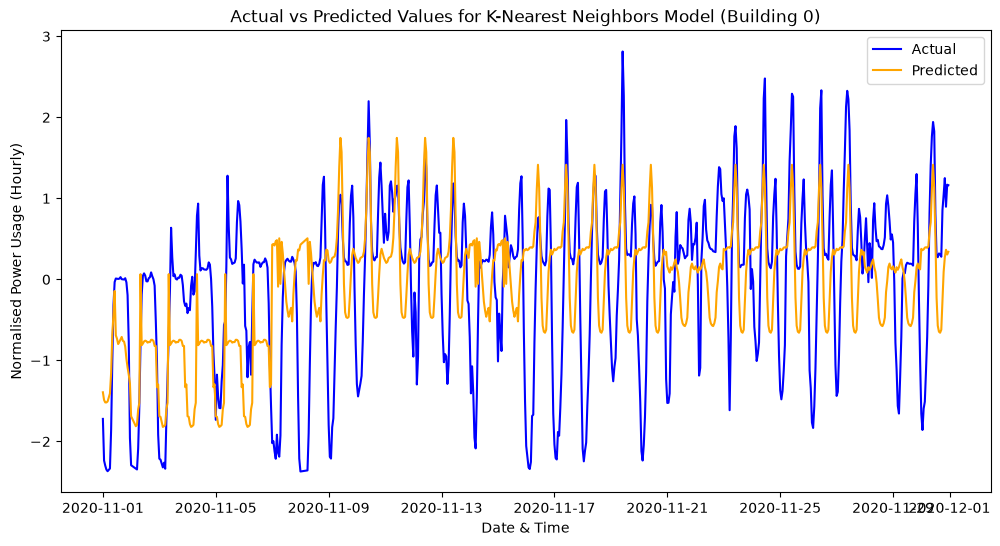

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for K-Nearest Neighbors Model (Building 0)")
plt.legend()
plt.show()

In [70]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (Y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 10.56%


### Building 1 October

In [33]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [34]:
cl = KNeighborsRegressor()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best parameters:")
print(grid_knn.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_knn.best_score_)
print(np.round(cv_rmse, 3))

cl = grid_knn.best_estimator_


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}

Best CV RMSE:
0.642

Test results:
RMSE: 0.653
MAE: 0.468
R²: 0.573


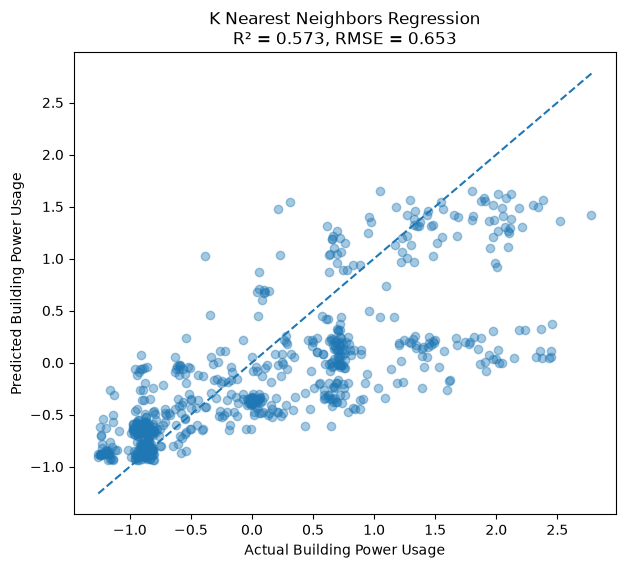

In [35]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building Power Usage')
plt.ylabel('Predicted Building Power Usage')

plt.title(
    'K Nearest Neighbors Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

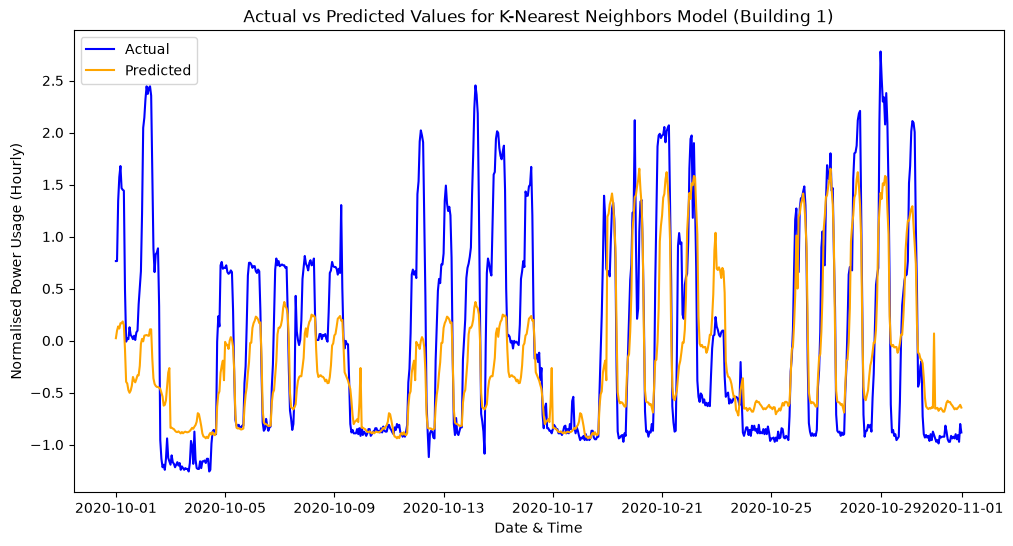

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for K-Nearest Neighbors Model (Building 1)")
plt.legend()
plt.show()

In [37]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (Y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 27.42%


### Building 1 November

In [71]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

In [72]:
cl = KNeighborsRegressor()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    cl,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best parameters:")
print(grid_knn.best_params_)

print("\nBest CV RMSE:")
cv_rmse = np.sqrt(-grid_knn.best_score_)
print(np.round(cv_rmse, 3))

cl = grid_knn.best_estimator_


Y_pred = cl.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, Y_pred))
mae = mean_absolute_error(y_test, Y_pred)
r2 = r2_score(y_test, Y_pred)

print("\nTest results:")
print("RMSE:", np.round(rmse, 3))
print("MAE:", np.round(mae, 3))
print("R²:", np.round(r2, 3))

Best parameters:
{'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}

Best CV RMSE:
0.639

Test results:
RMSE: 0.526
MAE: 0.391
R²: 0.723


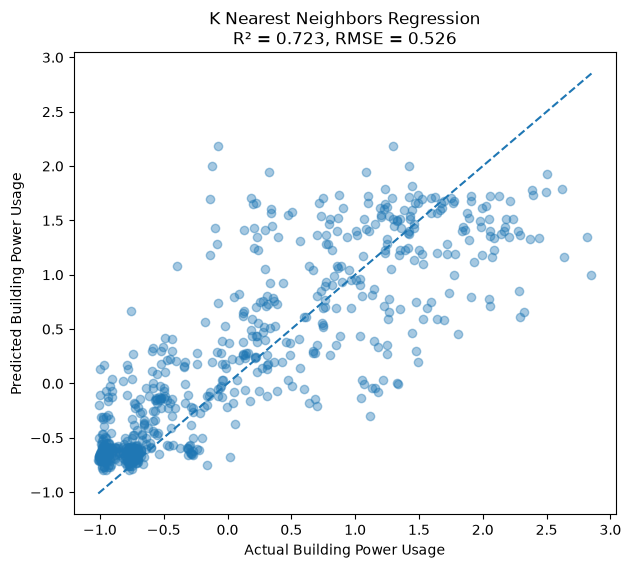

In [73]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, Y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Building Power Usage')
plt.ylabel('Predicted Building Power Usage')

plt.title(
    'K Nearest Neighbors Regression\n'
    f'R² = {r2:.3f}, RMSE = {rmse:.3f}'
)

plt.show()

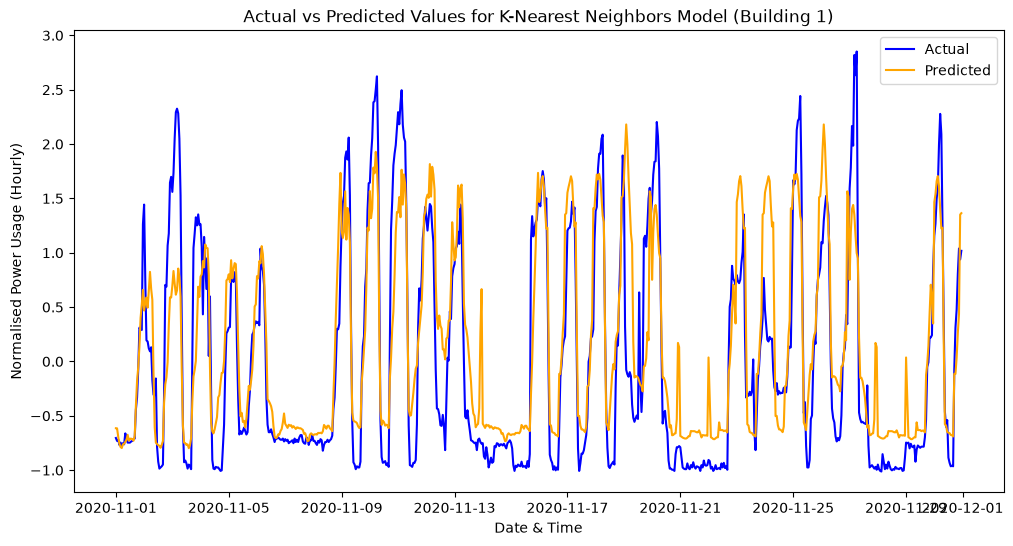

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual", color="blue")
plt.plot(y_test.index, Y_pred,label="Predicted", color="orange")
plt.xlabel("Date & Time")
plt.ylabel("Normalised Power Usage (Hourly)")
plt.title("Actual vs Predicted Values for K-Nearest Neighbors Model (Building 1)")
plt.legend()
plt.show()

In [75]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (Y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 32.08%


# Neural Networks

### Building 0 October

In [30]:
%pip install tensorflow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.5.3 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.3 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.3 which is incompatible.
scipy 1.13.1 requires numpy<2.3,>=1.22.4, but you have numpy 2.5.3 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.36.2 which is incompatible.



   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
    --------------------------------------- 7.9/350.9 MB 40.4 MB/s eta 0:00:09
   -- ------------------------------------- 18.6/350.9 MB 45.2 MB/s eta 0:00:08
   --- ------------------------------------ 29.6/350.9 MB 47.0 MB/s eta 0:00:07
   --- ------------------------------------ 33.0/350.9 MB 39.6 MB/s eta 0:00:09
   ---- ----------------------------------- 43.3/350.9 MB 41.1 MB/s eta 0:00:08
   ----- ---------------------------------- 51.9/350.9 MB 40.8 MB/s eta 0:00:08
   ------ --------------------------------- 60.0/350.9 MB 40.7 MB/s eta 0:00:08
   ------- -------------------------------- 69.5/350.9 MB 41.4 MB/s eta 0:00:07
   --------- ------------------------------ 79.7/350.9 MB 42.0 MB/s eta 0:00:07
   ---------- ----------------------------- 88.3/350.9 MB 42.1 MB/s eta 0:00:07
   ----------- ---------------------------- 97.5/350.9 MB 42.0 MB/s eta 0:00:07
   ----------- --------------------------- 107.0/

In [2]:
%pip install git+https://github.com/tensorflow/docs

  Cloning https://github.com/tensorflow/docs to c:\users\alpay\appdata\local\temp\pip-req-build-1w0jzine
  Resolved https://github.com/tensorflow/docs to commit a7aba9d3659fa2b521165d263a6012b110b0ab5f
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for tensorflow-docs: filename=tensorflow_docs-2026.7.9.49590-py3-none-any.whl size=188771 sha256=6bc088e87f165bb33e80ffedb9859de2dd6b5da9e1ebbbbcd5915b7dde2397b8
  Stored in directory: C:\Users\alpay\AppData\Local\Temp\pip-ephem-wheel-cache-y1b2rksu\wheels\3e\88\34\48d2789bc9d37b33ddce06bccc454fae0285e5396d0a5be9d9
Successfully built tensorflow-docs
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs 'C:\Users\alpay\AppData\Local\Temp\pip-req-build-1w0jzine'


In [23]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import layers
from tensorflow.keras import regularizers

from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense
from tensorflow.keras.optimizers import SGD


import tensorflow_docs as tfdocs
import tensorflow_docs.modeling
import tensorflow_docs.plots


I0000 00:00:1791507112.788880    7152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791507112.846978    7152 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791507115.914799    7152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [24]:


gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [25]:
X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-09-01"]
y_train_nn = y_train.loc[y_train.index < "2020-09-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-09-01") &
    (X_train.index < "2020-10-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-09-01") &
    (y_train.index < "2020-10-01")
]

In [26]:
def get_callbacks():
  return [
    tfdocs.modeling.EpochDots(report_every=20),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='auto',
                                     patience=10, restore_best_weights=True),
  ]

In [27]:
tf.keras.utils.set_random_seed(42)

model = Sequential()

model.add(keras.Input(shape=(X_train.shape[1],)))

model.add(Dense(32, activation="relu"))
model.add(Dense(32, activation="relu"))

model.add(Dense(1))

weights = model.get_weights();

model.summary()

I0000 00:00:1791507131.368697    7152 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,889 (7.38 KB)

 Trainable params: 1,889 (7.38 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
opt = SGD(learning_rate=0.01)
model.compile(loss="mean_absolute_error", optimizer=opt, metrics=["mae"])

In [29]:
NN_Model = model.fit(X_train_nn, y_train_nn, epochs = 200, validation_data=(X_val, y_val), callbacks=get_callbacks(), verbose = 1)

Epoch 1/200


I0000 00:00:1791507138.344802    7152 service.cc:154] XLA service 0x32c68350 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791507138.344882    7152 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9 (Driver: 13.1.0[591.94.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791507138.360212    7152 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791507146.375901    7152 cuda_dnn.cc:442] Loaded cuDNN version 92700


   6/1141 ━━━━━━━━━━━━━━━━━━━━ 25s 22ms/step - loss: 0.4711 - mae: 0.4711  

I0000 00:00:1791507147.325666    7152 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1141/1141 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.3347 - mae: 0.3347
Epoch: 0, loss:0.3347,  mae:0.3347,  val_loss:0.4887,  val_mae:0.4887,  
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - loss: 0.3347 - mae: 0.3347 - val_loss: 0.4887 - val_mae: 0.4887
Epoch 2/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 0.2700 - mae: 0.2700 - val_loss: 0.4161 - val_mae: 0.4161
Epoch 3/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - loss: 0.2508 - mae: 0.2508 - val_loss: 0.3799 - val_mae: 0.3799
Epoch 4/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 0.2441 - mae: 0.2441 - val_loss: 0.3730 - val_mae: 0.3730
Epoch 5/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 0.2404 - mae: 0.2404 - val_loss: 0.3645 - val_mae: 0.3645
Epoch 6/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.2384 - mae: 0.2384 - val_loss: 0.3609 - val_mae: 0.3609
Epoch 7/200
1141/1141 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.2367 - mae: 0.2367 - val_loss: 0.3534 - val_mae: 0.3534
Epoch 8/

In [30]:
best_epoch = np.argmin(NN_Model.history["val_mae"]) + 1
best_val_mae = np.min(NN_Model.history["val_mae"])

print("Best epoch:", best_epoch)
print("Best validation MAE:", best_val_mae)

Best epoch: 7
Best validation MAE: 0.3534460961818695


In [31]:
final_model = keras.models.clone_model(model)

final_model.compile(loss="mean_absolute_error", optimizer=keras.optimizers.deserialize(
        keras.optimizers.serialize(model.optimizer)), metrics=["mae"])

final_history = final_model.fit(
    X_train,
    y_train,
    epochs=7,
    verbose=1
)

Epoch 1/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - loss: 0.3241 - mae: 0.3241
Epoch 2/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - loss: 0.2643 - mae: 0.2643
Epoch 3/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - loss: 0.2500 - mae: 0.2500
Epoch 4/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - loss: 0.2438 - mae: 0.2438
Epoch 5/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - loss: 0.2401 - mae: 0.2401
Epoch 6/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - loss: 0.2376 - mae: 0.2376
Epoch 7/7
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - loss: 0.2358 - mae: 0.2358


In [32]:
y_pred = final_model.predict(X_test).flatten()

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Test MAE: 0.8719640917954743
Test RMSE: 1.184237612451232
Test R²: -0.4043215975376062


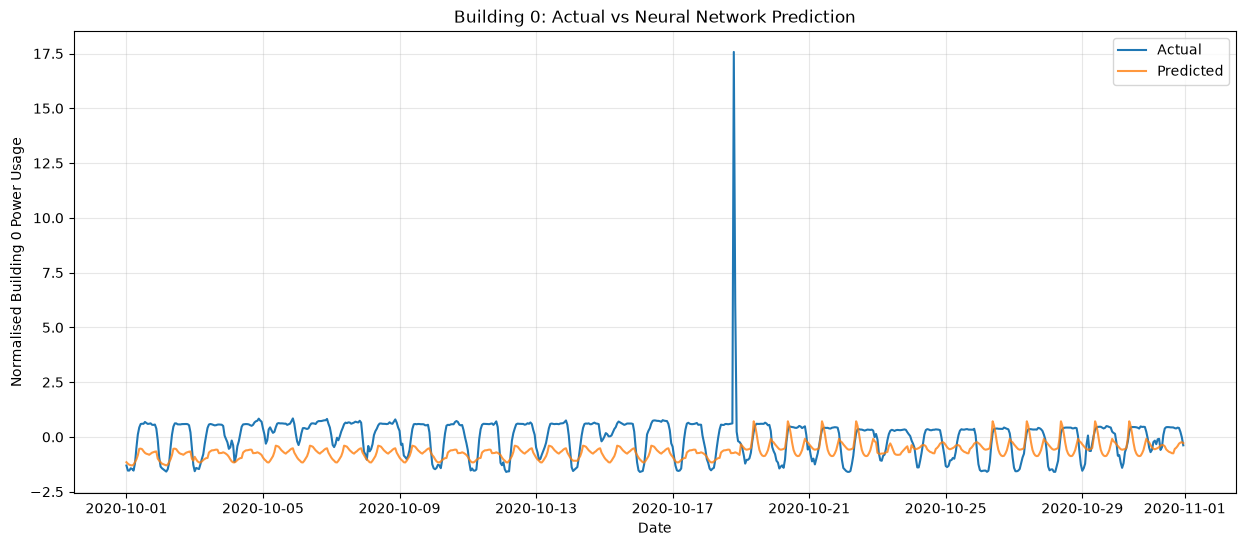

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual"
)

plt.plot(
    y_test.index,
    y_pred,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Normalised Building 0 Power Usage")
plt.title("Building 0: Actual vs Neural Network Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 7.72%


### Building 0 November

In [164]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import layers
from tensorflow.keras import regularizers

from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense
from tensorflow.keras.optimizers import SGD


import tensorflow_docs as tfdocs
import tensorflow_docs.modeling
import tensorflow_docs.plots


In [180]:
X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-10-01"]
y_train_nn = y_train.loc[y_train.index < "2020-10-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-10-01") &
    (X_train.index < "2020-11-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-10-01") &
    (y_train.index < "2020-11-01")
]

In [181]:
def get_callbacks():
  return [
    tfdocs.modeling.EpochDots(report_every=20),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='auto',
                                     patience=10, restore_best_weights=True),
  ]

In [205]:
tf.keras.utils.set_random_seed(42)

model = Sequential()

model.add(keras.Input(shape=(X_train.shape[1],)))

model.add(Dense(128, activation="relu"))
model.add(Dense(128, activation="relu"))


model.add(Dense(1))

weights = model.get_weights();

model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_43 (Dense)                │ (None, 128)            │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,841 (77.50 KB)

 Trainable params: 19,841 (77.50 KB)

 Non-trainable params: 0 (0.00 B)

In [206]:
opt = SGD(learning_rate=0.01)
model.compile(loss="mean_absolute_error", optimizer=opt, metrics=["mae"])

NN_Model = model.fit(X_train_nn, y_train_nn, epochs = 200, validation_data=(X_val, y_val), callbacks=get_callbacks(), verbose = 1)

Epoch 1/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2973 - mae: 0.2973
Epoch: 0, loss:0.2973,  mae:0.2973,  val_loss:0.7028,  val_mae:0.7028,  
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.2973 - mae: 0.2973 - val_loss: 0.7028 - val_mae: 0.7028
Epoch 2/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2500 - mae: 0.2500 - val_loss: 0.6452 - val_mae: 0.6452
Epoch 3/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2399 - mae: 0.2399 - val_loss: 0.5831 - val_mae: 0.5831
Epoch 4/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2355 - mae: 0.2355 - val_loss: 0.5550 - val_mae: 0.5550
Epoch 5/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.2328 - mae: 0.2328 - val_loss: 0.5263 - val_mae: 0.5263
Epoch 6/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2307 - mae: 0.2307 - val_loss: 0.5152 - val_mae: 0.5152
Epoch 7/200
1163/1163 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2292 - mae: 0.2292 - val_loss: 0.4958 - val_mae: 0.4958
Epoch 8/

In [207]:
best_epoch = np.argmin(NN_Model.history["val_mae"]) + 1
best_val_mae = np.min(NN_Model.history["val_mae"])

print("Best epoch:", best_epoch)
print("Best validation MAE:", best_val_mae)

Best epoch: 55
Best validation MAE: 0.3753829002380371


In [208]:
final_model = keras.models.clone_model(model)

final_model.compile(loss="mean_absolute_error", optimizer=keras.optimizers.deserialize(
        keras.optimizers.serialize(model.optimizer)), metrics=["mae"])

final_history = final_model.fit(
    X_train,
    y_train,
    epochs=55,
    verbose=1
)

Epoch 1/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2968 - mae: 0.2968
Epoch 2/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2533 - mae: 0.2533
Epoch 3/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2435 - mae: 0.2435
Epoch 4/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2380 - mae: 0.2380
Epoch 5/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2347 - mae: 0.2347
Epoch 6/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2320 - mae: 0.2320
Epoch 7/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2303 - mae: 0.2303
Epoch 8/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2288 - mae: 0.2288
Epoch 9/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2276 - mae: 0.2276
Epoch 10/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2266 - mae: 0.2266
Epoch 11/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2254 - mae: 0.2254
Epoch 12/55
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.2247 - mae: 0.2247
E

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Test MAE: 0.8749684752162642
Test RMSE: 0.9850737728853628
Test R²: 0.02826101551637783


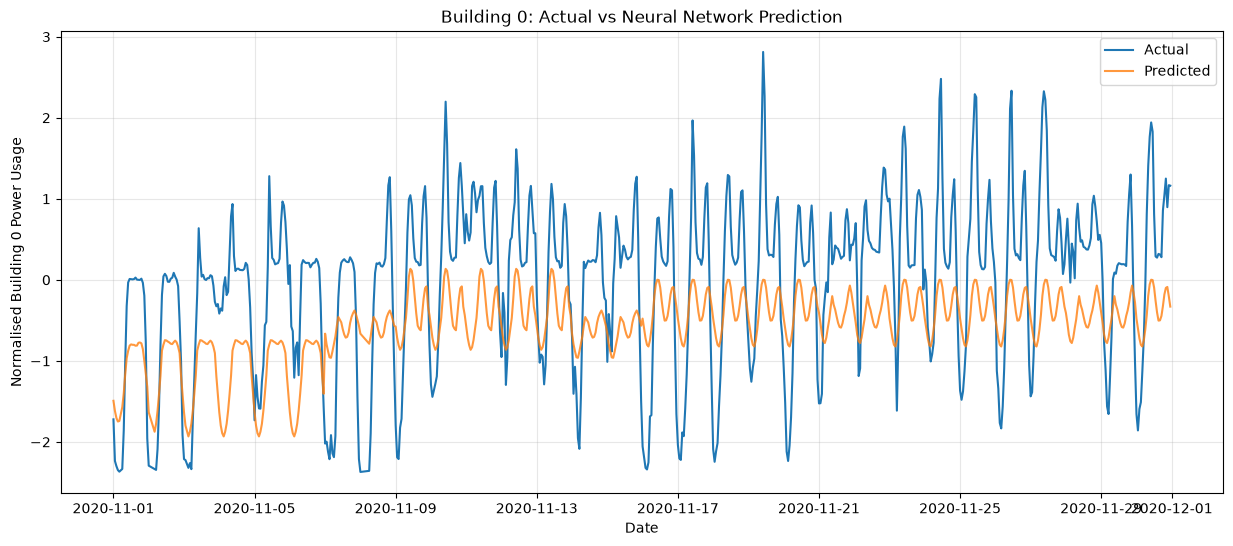

In [209]:
y_pred = final_model.predict(X_test).flatten()

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual"
)

plt.plot(
    y_test.index,
    y_pred,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Normalised Building 0 Power Usage")
plt.title("Building 0: Actual vs Neural Network Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [211]:
y_test_denormed = (y_test * TRAIN_STD0) + TRAIN_MEAN0
y_pred_denormed = (y_pred * TRAIN_STD0) + TRAIN_MEAN0

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 4.08%


### Building 1 October

In [115]:

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-09-01"]
y_train_nn = y_train.loc[y_train.index < "2020-09-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-09-01") &
    (X_train.index < "2020-10-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-09-01") &
    (y_train.index < "2020-10-01")
]

In [116]:
tf.keras.utils.set_random_seed(42)

model = Sequential()

model.add(keras.Input(shape=(X_train.shape[1],)))

model.add(Dense(32, activation="relu"))
model.add(Dense(32, activation="relu"))

model.add(Dense(1))

weights = model.get_weights();

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,953 (7.63 KB)

 Trainable params: 1,953 (7.63 KB)

 Non-trainable params: 0 (0.00 B)

In [117]:
opt = SGD(learning_rate=0.01)
model.compile(loss="mean_absolute_error", optimizer=opt, metrics=["mae"])

In [118]:
NN_Model = model.fit(X_train_nn, y_train_nn, epochs = 200, validation_data=(X_val, y_val), callbacks=get_callbacks(), verbose = 1)

Epoch 1/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5651 - mae: 0.5651
Epoch: 0, loss:0.5651,  mae:0.5651,  val_loss:0.2886,  val_mae:0.2886,  
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5651 - mae: 0.5651 - val_loss: 0.2886 - val_mae: 0.2886
Epoch 2/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4047 - mae: 0.4047 - val_loss: 0.2600 - val_mae: 0.2600
Epoch 3/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3721 - mae: 0.3721 - val_loss: 0.2425 - val_mae: 0.2425
Epoch 4/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3561 - mae: 0.3561 - val_loss: 0.2406 - val_mae: 0.2406
Epoch 5/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3458 - mae: 0.3458 - val_loss: 0.2356 - val_mae: 0.2356
Epoch 6/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3389 - mae: 0.3389 - val_loss: 0.2313 - val_mae: 0.2313
Epoch 7/200
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3333 - mae: 0.3333 - val_loss: 0.2324 - val_mae: 0.2324
Epoch 8/200
451/451 ━━━━

In [119]:
best_epoch = np.argmin(NN_Model.history["val_mae"]) + 1
best_val_mae = np.min(NN_Model.history["val_mae"])

print("Best epoch:", best_epoch)
print("Best validation MAE:", best_val_mae)



Best epoch: 23
Best validation MAE: 0.1945124715566635


In [120]:
final_model = keras.models.clone_model(model)

final_model.compile(loss="mean_absolute_error", optimizer=keras.optimizers.deserialize(
        keras.optimizers.serialize(model.optimizer)), metrics=["mae"])

final_history = final_model.fit(
    X_train,
    y_train,
    epochs=23,
    verbose=1
)

Epoch 1/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5114 - mae: 0.5114
Epoch 2/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3528 - mae: 0.3528
Epoch 3/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3342 - mae: 0.3342
Epoch 4/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3245 - mae: 0.3245
Epoch 5/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3174 - mae: 0.3174
Epoch 6/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3116 - mae: 0.3116
Epoch 7/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3066 - mae: 0.3066
Epoch 8/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3020 - mae: 0.3020
Epoch 9/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2978 - mae: 0.2978
Epoch 10/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2939 - mae: 0.2939
Epoch 11/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2904 - mae: 0.2904
Epoch 12/23
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2873 - mae: 0.2873
Epoch 13/23
496/496 ━━━━━

In [121]:
y_pred = final_model.predict(X_test).flatten()

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Test MAE: 0.4266510218122671
Test RMSE: 0.6379481387447057
Test R²: 0.5924561391320713


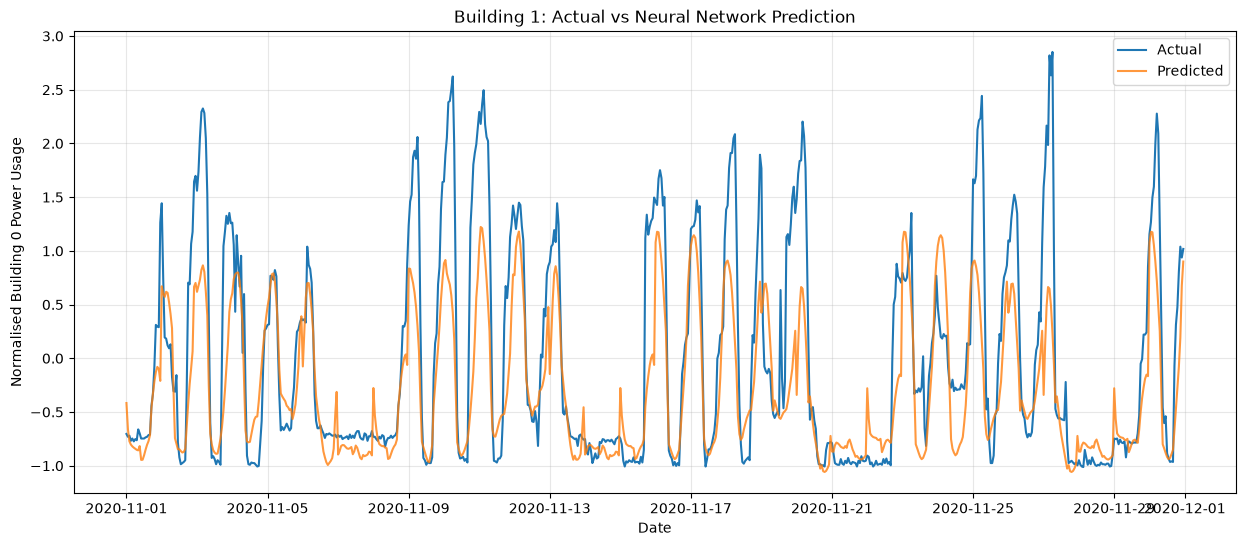

In [122]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual"
)

plt.plot(
    y_test.index,
    y_pred,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Normalised Building 0 Power Usage")
plt.title("Building 1: Actual vs Neural Network Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [123]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 36.67%


### Building 1 November

In [124]:

X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-10-01"]
y_train_nn = y_train.loc[y_train.index < "2020-10-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-10-01") &
    (X_train.index < "2020-11-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-10-01") &
    (y_train.index < "2020-11-01")
]

In [125]:
tf.keras.utils.set_random_seed(42)

model = Sequential()

model.add(keras.Input(shape=(X_train.shape[1],)))

model.add(Dense(32, activation="relu"))
model.add(Dense(32, activation="relu"))

model.add(Dense(1))

weights = model.get_weights();

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,953 (7.63 KB)

 Trainable params: 1,953 (7.63 KB)

 Non-trainable params: 0 (0.00 B)

In [126]:
opt = SGD(learning_rate=0.01)
model.compile(loss="mean_absolute_error", optimizer=opt, metrics=["mae"])

NN_Model = model.fit(X_train_nn, y_train_nn, epochs = 200, validation_data=(X_val, y_val), callbacks=get_callbacks(), verbose = 1)

Epoch 1/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5482 - mae: 0.5482
Epoch: 0, loss:0.5482,  mae:0.5482,  val_loss:0.2900,  val_mae:0.2900,  
473/473 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.5482 - mae: 0.5482 - val_loss: 0.2900 - val_mae: 0.2900
Epoch 2/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3958 - mae: 0.3958 - val_loss: 0.2945 - val_mae: 0.2945
Epoch 3/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3627 - mae: 0.3627 - val_loss: 0.2850 - val_mae: 0.2850
Epoch 4/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3455 - mae: 0.3455 - val_loss: 0.2733 - val_mae: 0.2733
Epoch 5/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3359 - mae: 0.3359 - val_loss: 0.2747 - val_mae: 0.2747
Epoch 6/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3295 - mae: 0.3295 - val_loss: 0.2723 - val_mae: 0.2723
Epoch 7/200
473/473 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3241 - mae: 0.3241 - val_loss: 0.2621 - val_mae: 0.2621
Epoch 8/200
473/473 ━━━━

In [128]:
best_epoch = np.argmin(NN_Model.history["val_mae"]) + 1
best_val_mae = np.min(NN_Model.history["val_mae"])

print("Best epoch:", best_epoch)
print("Best validation MAE:", best_val_mae)



Best epoch: 29
Best validation MAE: 0.24925361573696136


In [130]:
final_model = keras.models.clone_model(model)

final_model.compile(loss="mean_absolute_error", optimizer=keras.optimizers.deserialize(
        keras.optimizers.serialize(model.optimizer)), metrics=["mae"])

final_history = final_model.fit(
    X_train,
    y_train,
    epochs=29,
    verbose=1
)

Epoch 1/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4611 - mae: 0.4611
Epoch 2/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3500 - mae: 0.3500
Epoch 3/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3293 - mae: 0.3293
Epoch 4/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3170 - mae: 0.3170
Epoch 5/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3081 - mae: 0.3081
Epoch 6/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3017 - mae: 0.3017
Epoch 7/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2968 - mae: 0.2968
Epoch 8/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2929 - mae: 0.2929
Epoch 9/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2899 - mae: 0.2899
Epoch 10/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2872 - mae: 0.2872
Epoch 11/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2847 - mae: 0.2847
Epoch 12/29
496/496 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2825 - mae: 0.2825
Epoch 13/29
496/496 ━━━━━

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Test MAE: 0.4327447638852697
Test RMSE: 0.6352922163922322
Test R²: 0.5958424698885125


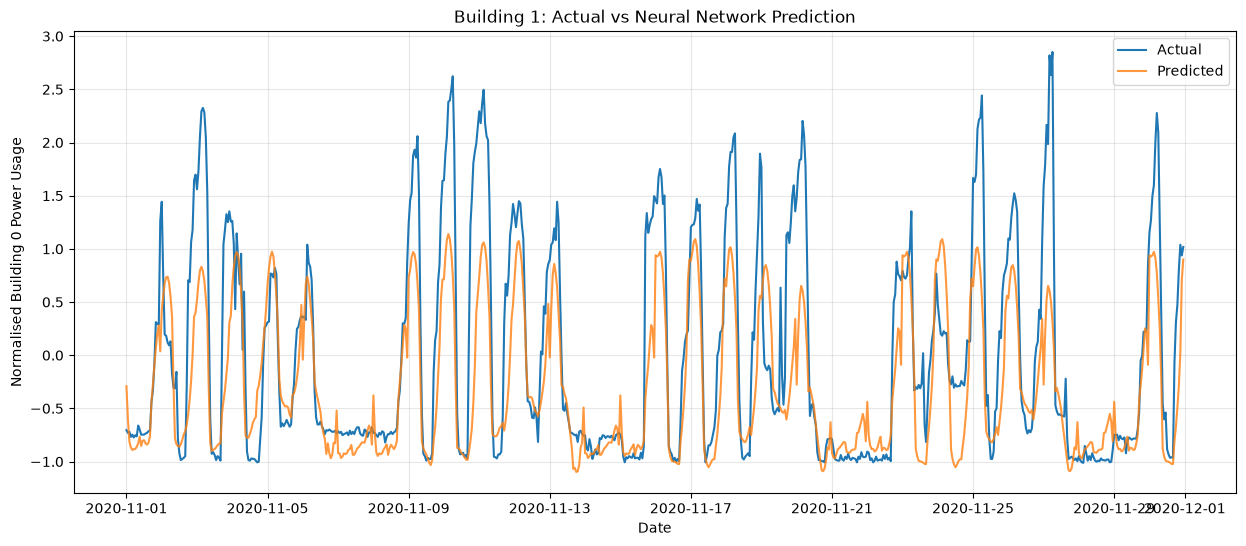

In [131]:
y_pred = final_model.predict(X_test).flatten()

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual"
)

plt.plot(
    y_test.index,
    y_pred,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Normalised Building 0 Power Usage")
plt.title("Building 1: Actual vs Neural Network Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [132]:
y_test_denormed = (y_test * TRAIN_STD1) + TRAIN_MEAN1
y_pred_denormed = (y_pred * TRAIN_STD1) + TRAIN_MEAN1

valid = y_test_denormed != 0

percentage_error = np.abs(
    (y_test_denormed[valid] - y_pred_denormed[valid])
    / y_test_denormed[valid]
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Predictions within ±10% = {:.2f}%".format(within_10))

Predictions within ±10% = 37.92%


# XGBoost


### Building 0 October



In [265]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 36.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 33.3 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


In [65]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [77]:
X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]



In [78]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

tscv = TimeSeriesSplit(n_splits=5, test_size = 720)

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END 

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 300, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...test_size=720)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more a

In [83]:
print("Best parameters:", grid_xgb.best_params_)
print("Best CV MAE:", -grid_xgb.best_score_)


Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 500, 'subsample': 1.0}
Best CV MAE: 30.316286093393963


In [84]:
y_pred_xgb = grid_xgb.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred_xgb)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
test_r2 = r2_score(y_test, y_pred_xgb)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Test MAE: 28.283664826390545
Test RMSE: 57.37887646059528
Test R²: 0.3144856801053344


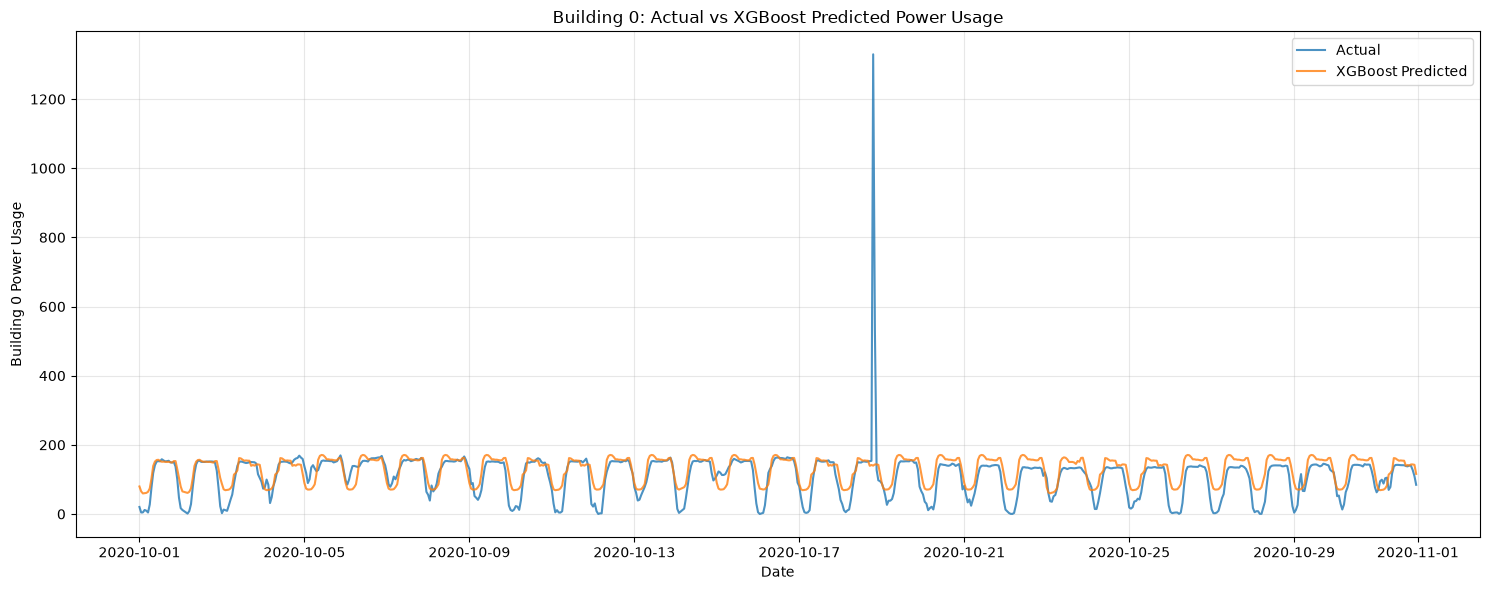

In [85]:
import matplotlib.pyplot as plt



plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred_xgb,
    label="XGBoost Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Building 0 Power Usage")
plt.title("Building 0: Actual vs XGBoost Predicted Power Usage")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [86]:
percentage_error = np.abs((y_test - y_pred_xgb) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 35.77 %


### Building 0 November

In [145]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [146]:
X_train = Building_0_feature.drop(columns=["Building0"])
y_train = Building_0_feature["Building0"]


X_test = Nov_0_testing.drop(columns=["Building0"])
y_test = Nov_0_testing["Building0"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-10-01"]
y_train_nn = y_train.loc[y_train.index < "2020-10-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-10-01") &
    (X_train.index < "2020-11-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-10-01") &
    (y_train.index < "2020-11-01")
]

In [147]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train_nn, y_train_nn)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   1.7s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=500, subsample=0.8; total time=   1.8s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=300, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=300, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estima

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 300, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more a

In [148]:
X_final_train = X_train.loc[X_train.index < "2020-11-01"]
y_final_train = y_train.loc[y_train.index < "2020-11-01"]

final_xgb = XGBRegressor(
    **grid_xgb.best_params_,
    objective="reg:squarederror",
    random_state=42
)

final_xgb.fit(X_final_train, y_final_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [149]:
y_pred_xgb = final_xgb.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred_xgb)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
test_r2 = r2_score(y_test, y_pred_xgb)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Test MAE: 36.80434859960852
Test RMSE: 52.329094092653534
Test R²: 0.22363781477607192


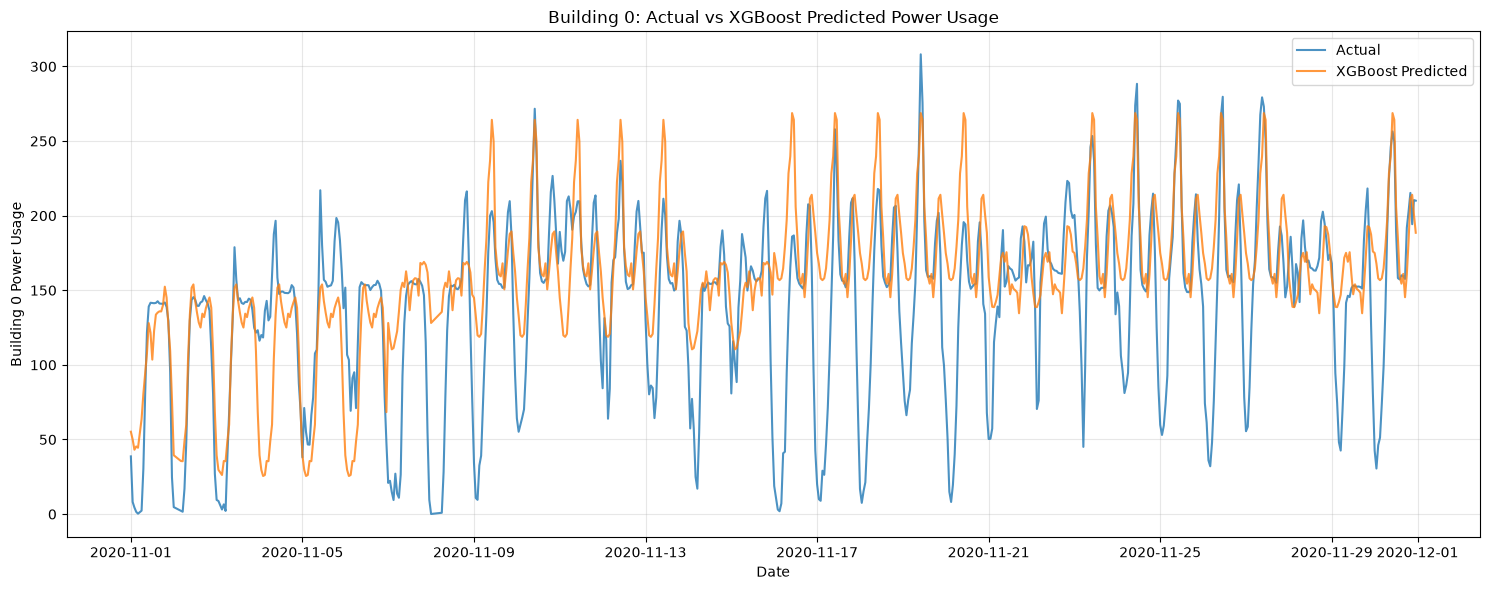

Within 10% accuracy: 38.31 %


In [150]:
import matplotlib.pyplot as plt



plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred_xgb,
    label="XGBoost Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Building 0 Power Usage")
plt.title("Building 0: Actual vs XGBoost Predicted Power Usage")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

percentage_error = np.abs((y_test - y_pred_xgb) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

### Building 1 October

In [87]:
X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]



In [88]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

tscv = TimeSeriesSplit(n_splits=5, test_size = 720)

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=300, subsample=1.0; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   1.9s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   2.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   2.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   2.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   2.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   2.0s
[CV] END 

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 300, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...test_size=720)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more a

In [89]:
y_pred_xgb = grid_xgb.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred_xgb)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
test_r2 = r2_score(y_test, y_pred_xgb)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Test MAE: 0.9391272391042402
Test RMSE: 1.3937100723095768
Test R²: 0.7929827142680065


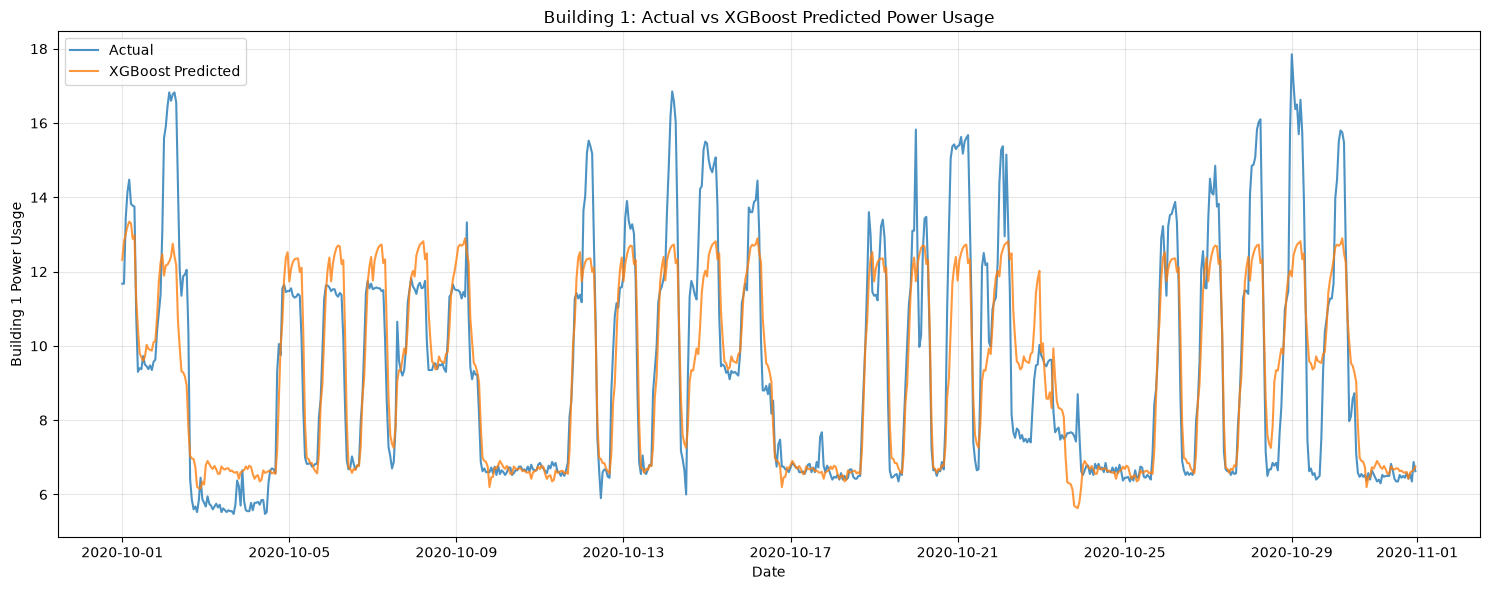

In [90]:
import matplotlib.pyplot as plt



plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred_xgb,
    label="XGBoost Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Building 1 Power Usage")
plt.title("Building 1: Actual vs XGBoost Predicted Power Usage")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [91]:


percentage_error = np.abs((y_test - y_pred_xgb) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 65.86 %


### Building 1 November

In [151]:
X_train = Building_1_feature.drop(columns=["Building1"])
y_train = Building_1_feature["Building1"]


X_test = Nov_1_testing.drop(columns=["Building1"])
y_test = Nov_1_testing["Building1"]

X_train_medians = X_train.median()

X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)


y_train = y_train.fillna(y_train.median())

valid = y_test.notna()

X_test = X_test.loc[valid]
y_test = y_test.loc[valid]

X_train_nn = X_train.loc[X_train.index < "2020-10-01"]
y_train_nn = y_train.loc[y_train.index < "2020-10-01"]

X_val = X_train.loc[
    (X_train.index >= "2020-10-01") &
    (X_train.index < "2020-11-01")
]

y_val = y_train.loc[
    (y_train.index >= "2020-10-01") &
    (y_train.index < "2020-11-01")
]

In [152]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train_nn, y_train_nn)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=2, n_estimators=100, subsample=1.0; total time=   0.1s
[CV] END 

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 300, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more a

In [153]:
X_final_train = X_train.loc[X_train.index < "2020-10-01"]
y_final_train = y_train.loc[y_train.index < "2020-10-01"]

final_xgb = XGBRegressor(
    **grid_xgb.best_params_,
    objective="reg:squarederror",
    random_state=42
)

final_xgb.fit(X_final_train, y_final_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Test MAE: 2.215523679388894
Test RMSE: 2.7881564829967003
Test R²: 0.6481175978485822


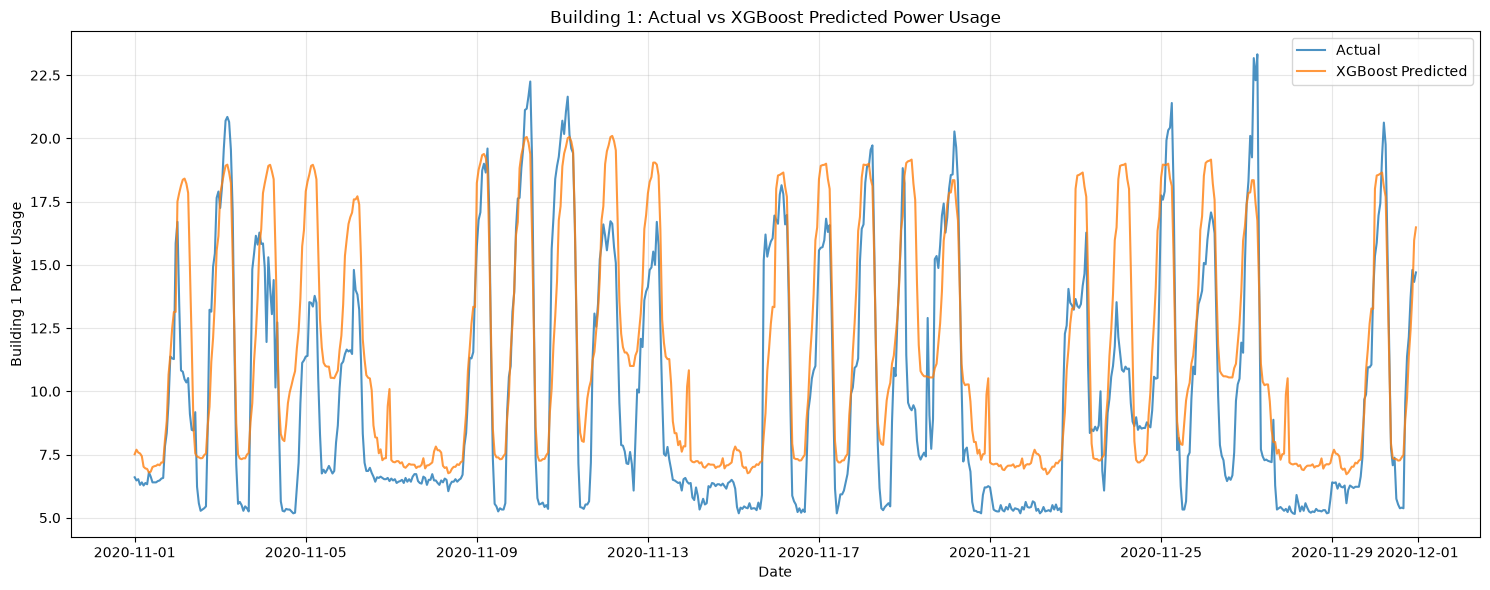

In [154]:
y_pred_xgb = final_xgb.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred_xgb)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
test_r2 = r2_score(y_test, y_pred_xgb)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

import matplotlib.pyplot as plt



plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_pred_xgb,
    label="XGBoost Predicted",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Building 1 Power Usage")
plt.title("Building 1: Actual vs XGBoost Predicted Power Usage")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [155]:


percentage_error = np.abs((y_test - y_pred_xgb) / y_test) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("Within 10% accuracy:", round(within_10, 2), "%")

Within 10% accuracy: 22.78 %
